In [2]:
import ast

file_path = 'D:\\Licenta\\meta_Electronics.json\\meta_Electronics.json'
output_file = 'ierarhie_categorii.txt'

class TreeNode:
    def __init__(self, name):
        self.name = name
        self.count = 0
        self.children = {}

root = TreeNode("ROOT")

linii_procesate = 0

with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        linii_procesate += 1
        if linii_procesate % 50000 == 0:
            print(f"  -> {linii_procesate} linii procesate...")

        try:
            try:
                item = ast.literal_eval(line.strip())
            except:
                item = eval(line.strip())

            categories = item.get('categories', [])
            if not categories:
                continue

            added_paths = set()

            for path in categories:
                current_node = root

                full_path_id = ""

                for cat in path:
                    full_path_id += cat + "|"

                    if cat not in current_node.children:
                        current_node.children[cat] = TreeNode(cat)

                    current_node = current_node.children[cat]

                    if full_path_id not in added_paths:
                        current_node.count += 1
                        added_paths.add(full_path_id)

        except Exception:
            continue


def write_tree(node, file_obj, prefix="", is_last=True, depth=0, max_depth=None):
    # Dacă am atins adâncimea maximă dorită, ne oprim pe ramura asta
    if max_depth is not None and depth > max_depth:
        return

    # Nu printăm nodul invizibil ROOT
    if node.name != "ROOT":
        connector = "└── " if is_last else "├── "
        linie = f"{prefix}{connector}{node.name} ({node.count})"
        file_obj.write(linie + "\n")

        if depth <= 2:
            print(linie)

        if is_last:
            prefix += "    "
        else:
            prefix += "│   "

    children = sorted(node.children.values(), key=lambda x: x.count, reverse=True)
    for i, child in enumerate(children):
        write_tree(
            node=child,
            file_obj=file_obj,
            prefix=prefix,
            is_last=(i == len(children) - 1),
            depth=depth + 1,
            max_depth=max_depth
        )

with open(output_file, 'w', encoding='utf-8') as out_f:
    out_f.write("IERARHIA CATEGORIILOR AMAZON (Sortată după frecvență)\n")
    out_f.write("=====================================================\n")
    write_tree(root, out_f, max_depth=None)


  -> 50000 linii procesate...
  -> 100000 linii procesate...
  -> 150000 linii procesate...
  -> 200000 linii procesate...
  -> 250000 linii procesate...
  -> 300000 linii procesate...
  -> 350000 linii procesate...
  -> 400000 linii procesate...
  -> 450000 linii procesate...
├── Electronics (498196)
│   ├── Computers & Accessories (233684)
│   ├── Camera & Photo (94857)
│   ├── Accessories & Supplies (68026)
│   ├── Portable Audio & Video (35368)
│   ├── Car & Vehicle Electronics (25993)
│   ├── Television & Video (11437)
│   ├── Home Audio (9806)
│   ├── eBook Readers & Accessories (7489)
│   ├── GPS & Navigation (7078)
│   ├── Security & Surveillance (4330)
│   ├── Electronics Warranties (1239)
│   ├── Service & Replacement Plans (91)
│   └── Cell Phones & Accessories (4)
├── Cell Phones & Accessories (2684)
│   ├── Cases (1422)
│   ├── Accessories (1252)
│   ├── Cell Phones (21)
│   └── Connected Devices (12)
├── Kindle Store (597)
│   ├── Kindle Accessories (594)
│   └── Kindle e

In [4]:
file_path = 'D:\\Licenta\\meta_Electronics.json\\meta_Electronics.json'

import ast
import random
import numpy as np
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

TARGET_CLASSES = [
    'Film Photography', 'Digital Cameras', 'Binoculars & Scopes',
    'Lenses', 'Tripods & Monopods', 'Video Surveillance',
    'Lighting & Studio', 'Flashes',   'Video Cables', 'Audio Cables', 'TV Accessories & Parts',
    'Headphone Accessories', 'Connectors & Adapters', 'Media Storage & Organization',
    'Distribution', 'Telephone Accessories'
]
# TARGET_CLASSES = [
#     'Video Cables', 'Audio Cables', 'TV Accessories & Parts',
#     'Headphone Accessories', 'Connectors & Adapters', 'Media Storage & Organization',
#     'Distribution', 'Telephone Accessories'
# ]

def extract_target_class(categories):
    if not categories:
        return None
    for path in categories:
        for cat in path:
            if cat in TARGET_CLASSES:
                return cat
    return None

products = {}
edges = []

stats = {
    'linii_totale': 0,
    'linii_cu_target_string': 0,
    'parsate_cu_succes': 0,
    'erori_sintaxa_eval': 0,
    'lipsa_clasa_in_categorii': 0
}

with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        stats['linii_totale'] += 1

        try:
            try:
                import ast
                item = ast.literal_eval(line.strip())
            except:
                item = eval(line.strip())

            asin = item.get('asin')
            categories = item.get('categories', [])

            target_class = extract_target_class(categories)
            if target_class:
                title = item.get('title', '')
                description = item.get('description', '')
                text_content = f"{title} {description}"

                products[asin] = {
                    'class': target_class,
                    'text': text_content,
                    'related': item.get('related', {})
                }
                stats['parsate_cu_succes'] += 1
            else:
                stats['lipsa_clasa_in_categorii'] += 1

        except Exception as e:
            stats['erori_sintaxa_eval'] += 1
            if stats['erori_sintaxa_eval'] <= 3:
                print(f"\n[EROARE EXAMPLU] Linia a eșuat. Motiv: {e}")
                print(f"Linia: {line[:150]}...")

for k, v in stats.items():
    print(f"{k}: {v}")

print(f"\nAm extras {len(products)} produse valide în dicționar.")

linii_totale: 498196
linii_cu_target_string: 0
parsate_cu_succes: 65679
erori_sintaxa_eval: 0
lipsa_clasa_in_categorii: 432517

Am extras 65679 produse valide în dicționar.


In [1]:
import numpy as np
import scipy.sparse as sp


def eliminate_self_loops(A):
    """Remove self-loops from the adjacency matrix."""
    A = A.tolil()
    A.setdiag(0)
    A = A.tocsr()
    A.eliminate_zeros()
    return A


def largest_connected_components(sparse_graph, n_components=1):
    """Select the largest connected components in the graph.

    Parameters
    ----------
    sparse_graph : SparseGraph
        Input graph.
    n_components : int, default 1
        Number of largest connected components to keep.

    Returns
    -------
    sparse_graph : SparseGraph
        Subgraph of the input graph where only the nodes in largest n_components are kept.

    """
    _, component_indices = sp.csgraph.connected_components(sparse_graph.adj_matrix)
    component_sizes = np.bincount(component_indices)
    components_to_keep = np.argsort(component_sizes)[::-1][:n_components]  # reverse order to sort descending
    nodes_to_keep = [
        idx for (idx, component) in enumerate(component_indices) if component in components_to_keep
    ]
    return create_subgraph(sparse_graph, nodes_to_keep=nodes_to_keep)


def create_subgraph(sparse_graph, _sentinel=None, nodes_to_remove=None, nodes_to_keep=None):
    """Create a graph with the specified subset of nodes.

    Exactly one of (nodes_to_remove, nodes_to_keep) should be provided, while the other stays None.
    Note that to avoid confusion, it is required to pass node indices as named arguments to this function.

    Parameters
    ----------
    sparse_graph : SparseGraph
        Input graph.
    nodes_to_remove : array-like of int
        Indices of nodes that have to removed.
    nodes_to_keep : array-like of int
        Indices of nodes that have to be kept.

    Returns
    -------
    sparse_graph : SparseGraph
        Graph with specified nodes removed.

    """

    if nodes_to_remove is None and nodes_to_keep is None:
        raise ValueError("Either nodes_to_remove or nodes_to_keep must be provided.")
    elif nodes_to_remove is not None and nodes_to_keep is not None:
        raise ValueError("Only one of nodes_to_remove or nodes_to_keep must be provided.")
    elif nodes_to_remove is not None:
        nodes_to_keep = [i for i in range(sparse_graph.num_nodes()) if i not in nodes_to_remove]
    elif nodes_to_keep is not None:
        nodes_to_keep = sorted(nodes_to_keep)
    else:
        raise RuntimeError("This should never happen.")

    sparse_graph.adj_matrix = sparse_graph.adj_matrix[nodes_to_keep][:, nodes_to_keep]
    if sparse_graph.attr_matrix is not None:
        sparse_graph.attr_matrix = sparse_graph.attr_matrix[nodes_to_keep]
    if sparse_graph.labels is not None:
        sparse_graph.labels = sparse_graph.labels[nodes_to_keep]
    if sparse_graph.node_names is not None:
        sparse_graph.node_names = sparse_graph.node_names[nodes_to_keep]
    return sparse_graph



In [2]:
import numpy as np
import scipy.sparse as sp


class SparseGraph:
    """Attributed labeled graph stored in sparse matrix form.

    """
    def __init__(self, adj_matrix, attr_matrix=None, labels=None,
                 node_names=None, attr_names=None, class_names=None, metadata=None):
        """Create an attributed graph.

        Parameters
        ----------
        adj_matrix : sp.csr_matrix, shape [num_nodes, num_nodes]
            Adjacency matrix in CSR format.
        attr_matrix : sp.csr_matrix or np.ndarray, shape [num_nodes, num_attr], optional
            Attribute matrix in CSR or numpy format.
        labels : np.ndarray, shape [num_nodes], optional
            Array, where each entry represents respective node's label(s).
        node_names : np.ndarray, shape [num_nodes], optional
            Names of nodes (as strings).
        attr_names : np.ndarray, shape [num_attr]
            Names of the attributes (as strings).
        class_names : np.ndarray, shape [num_classes], optional
            Names of the class labels (as strings).
        metadata : object
            Additional metadata such as text.

        """
        # Make sure that the dimensions of matrices / arrays all agree
        if sp.isspmatrix(adj_matrix):
            adj_matrix = adj_matrix.tocsr().astype(np.float32)
        else:
            raise ValueError("Adjacency matrix must be in sparse format (got {0} instead)"
                             .format(type(adj_matrix)))

        if adj_matrix.shape[0] != adj_matrix.shape[1]:
            raise ValueError("Dimensions of the adjacency matrix don't agree")

        if attr_matrix is not None:
            if sp.isspmatrix(attr_matrix):
                attr_matrix = attr_matrix.tocsr().astype(np.float32)
            elif isinstance(attr_matrix, np.ndarray):
                attr_matrix = attr_matrix.astype(np.float32)
            else:
                raise ValueError("Attribute matrix must be a sp.spmatrix or a np.ndarray (got {0} instead)"
                                 .format(type(attr_matrix)))

            if attr_matrix.shape[0] != adj_matrix.shape[0]:
                raise ValueError("Dimensions of the adjacency and attribute matrices don't agree")

        if labels is not None:
            if labels.shape[0] != adj_matrix.shape[0]:
                raise ValueError("Dimensions of the adjacency matrix and the label vector don't agree")

        if node_names is not None:
            if len(node_names) != adj_matrix.shape[0]:
                raise ValueError("Dimensions of the adjacency matrix and the node names don't agree")

        if attr_names is not None:
            if len(attr_names) != attr_matrix.shape[1]:
                raise ValueError("Dimensions of the attribute matrix and the attribute names don't agree")

        self.adj_matrix = adj_matrix
        self.attr_matrix = attr_matrix
        self.labels = labels
        self.node_names = node_names
        self.attr_names = attr_names
        self.class_names = class_names
        self.metadata = metadata

    def num_nodes(self):
        """Get the number of nodes in the graph."""
        return self.adj_matrix.shape[0]

    def num_edges(self):
        """Get the number of edges in the graph.

        For undirected graphs, (i, j) and (j, i) are counted as single edge.
        """
        if self.is_directed():
            return int(self.adj_matrix.nnz)
        else:
            return int(self.adj_matrix.nnz / 2)

    def get_neighbors(self, idx):
        """Get the indices of neighbors of a given node.

        Parameters
        ----------
        idx : int
            Index of the node whose neighbors are of interest.

        """
        return self.adj_matrix[idx].indices

    def is_directed(self):
        """Check if the graph is directed (adjacency matrix is not symmetric)."""
        return (self.adj_matrix != self.adj_matrix.T).sum() != 0

    def to_undirected(self):
        """Convert to an undirected graph (make adjacency matrix symmetric)."""
        if self.is_weighted():
            raise ValueError("Convert to unweighted graph first.")
        else:
            self.adj_matrix = self.adj_matrix + self.adj_matrix.T
            self.adj_matrix[self.adj_matrix != 0] = 1
        return self

    def is_weighted(self):
        """Check if the graph is weighted (edge weights other than 1)."""
        return np.any(np.unique(self.adj_matrix[self.adj_matrix != 0].A1) != 1)

    def to_unweighted(self):
        """Convert to an unweighted graph (set all edge weights to 1)."""
        self.adj_matrix.data = np.ones_like(self.adj_matrix.data)
        return self

    def standardize(self):
        """Select the LCC of the unweighted/undirected/no-self-loop graph.

        All changes are done inplace.

        """
        G = self.to_unweighted().to_undirected()
        G = eliminate_self_loops_adj(G)
        n_components, _ = sp.csgraph.connected_components(G.adj_matrix)
        print(n_components)
        G = largest_connected_components(G, 10)
        return G


def eliminate_self_loops_adj(G):
    G.adj_matrix = eliminate_self_loops(G.adj_matrix)
    return G


def save_sparse_graph_to_npz(filepath, sparse_graph):
    """Save a SparseGraph to a Numpy binary file.

    Parameters
    ----------
    filepath : str
        Name of the output file.
    sparse_graph : gust.SparseGraph
        Graph in sparse matrix format.

    """
    data_dict = {
        'adj_data': sparse_graph.adj_matrix.data,
        'adj_indices': sparse_graph.adj_matrix.indices,
        'adj_indptr': sparse_graph.adj_matrix.indptr,
        'adj_shape': sparse_graph.adj_matrix.shape
    }
    if sp.isspmatrix(sparse_graph.attr_matrix):
        data_dict['attr_data'] = sparse_graph.attr_matrix.data
        data_dict['attr_indices'] = sparse_graph.attr_matrix.indices
        data_dict['attr_indptr'] = sparse_graph.attr_matrix.indptr
        data_dict['attr_shape'] = sparse_graph.attr_matrix.shape
    elif isinstance(sparse_graph.attr_matrix, np.ndarray):
        data_dict['attr_matrix'] = sparse_graph.attr_matrix

    if sp.isspmatrix(sparse_graph.labels):
        data_dict['labels_data'] = sparse_graph.labels.data
        data_dict['labels_indices'] = sparse_graph.labels.indices
        data_dict['labels_indptr'] = sparse_graph.labels.indptr
        data_dict['labels_shape'] = sparse_graph.labels.shape
    elif isinstance(sparse_graph.labels, np.ndarray):
        data_dict['labels'] = sparse_graph.labels

    if sparse_graph.node_names is not None:
        data_dict['node_names'] = sparse_graph.node_names

    if sparse_graph.attr_names is not None:
        data_dict['attr_names'] = sparse_graph.attr_names

    if sparse_graph.class_names is not None:
        data_dict['class_names'] = sparse_graph.class_names

    if sparse_graph.metadata is not None:
        data_dict['metadata'] = sparse_graph.metadata

    if not filepath.endswith('.npz'):
        filepath += '.npz'

    np.savez(filepath, **data_dict)


In [5]:
import numpy as np
import scipy.sparse as sp
import re
from sklearn.feature_extraction.text import TfidfVectorizer

asin_list = list(products.keys())
asin_to_idx = {asin: idx for idx, asin in enumerate(asin_list)}
num_nodes_raw = len(asin_to_idx)
print(f"Produse brute: {num_nodes_raw}")

class_to_idx = {name: i for i, name in enumerate(TARGET_CLASSES)}
labels_raw = np.zeros(num_nodes_raw, dtype=np.int64)
texts_raw  = [""] * num_nodes_raw

for asin, data in products.items():
    idx = asin_to_idx[asin]
    labels_raw[idx] = class_to_idx[data['class']]
    texts_raw[idx]  = data['text']

# Build adjacency matrix
edge_list = []
for asin, data in products.items():
    src_idx = asin_to_idx[asin]
    for target_asin in data.get('related', {}).get('also_bought', []):
        if target_asin in asin_to_idx:
            edge_list.append((src_idx, asin_to_idx[target_asin]))

if edge_list:
    edges_arr    = np.array(edge_list)
    adj_matrix_raw = sp.csr_matrix(
        (np.ones(len(edges_arr)), (edges_arr[:, 0], edges_arr[:, 1])),
        shape=(num_nodes_raw, num_nodes_raw)
    )
    adj_matrix_raw = adj_matrix_raw + adj_matrix_raw.T
    adj_matrix_raw[adj_matrix_raw > 1.0] = 1.0
else:
    adj_matrix_raw = sp.csr_matrix((num_nodes_raw, num_nodes_raw))

# ── STEP 1: filter structure first, features second ──────────────────────────
placeholder_attr = sp.eye(num_nodes_raw, format='csr', dtype=np.float32)

graph_struct = SparseGraph(
    adj_matrix  = adj_matrix_raw,
    attr_matrix = placeholder_attr,
    labels      = labels_raw,
    node_names  = np.array(asin_list),
    class_names = np.array(TARGET_CLASSES)
)

valid_text_mask = np.array([1 if texts_raw[i].strip() else 0
                             for i in range(num_nodes_raw)])
valid_node_indices = np.where(valid_text_mask > 0)[0]
graph_struct = create_subgraph(graph_struct, nodes_to_keep=valid_node_indices)

graph_struct = graph_struct.standardize()

print(f"Noduri rămase după filtrare structurală: {graph_struct.num_nodes()}")
print(f"Muchii rămase: {graph_struct.num_edges()}")

# ── STEP 2: fit TF-IDF ONLY on the surviving nodes ───────────────────────────
final_asins = graph_struct.node_names.tolist()
final_texts = [products[asin]['text'] for asin in final_asins]

# ── NEW: Clean HTML/XML/CSS noise from product text ──────────────────────────
def clean_text(text):
    """Strip HTML tags, MS Word XML conditionals, CSS blocks, HTML entities."""
    # Remove MS Word conditional comments: [if ...]...[endif]
    text = re.sub(r'\[if[^\]]*\].*?\[endif\]', ' ', text, flags=re.DOTALL)
    # Remove HTML/XML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remove HTML entities (&nbsp; &#123; etc.)
    text = re.sub(r'&[a-zA-Z0-9#]+;', ' ', text)
    # Remove CSS-like blocks { ... }
    text = re.sub(r'\{[^}]+\}', ' ', text)
    # Collapse whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

final_texts = [clean_text(t) for t in final_texts]

from sentence_transformers import SentenceTransformer

sbert_model = SentenceTransformer('all-mpnet-base-v2')  # 768-dim
embeddings = sbert_model.encode(
    final_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
).astype(np.float32)

attr_matrix_final = sp.csr_matrix(embeddings)  # scipy sparse for SparseGraph compat
print(f"SBERT embeddings: {attr_matrix_final.shape}")  # (19438, 768)

# Quick sanity check — show first 20 words

# ── STEP 3: assemble the final clean graph ────────────────────────────────────
graph_final = SparseGraph(
    adj_matrix  = graph_struct.adj_matrix,
    attr_matrix = attr_matrix_final,
    labels      = graph_struct.labels,
    node_names  = graph_struct.node_names,
    class_names = np.array(TARGET_CLASSES)
)

save_sparse_graph_to_npz('my_amazon_photo_custom.npz', graph_final)
print("Graf salvat.")

Produse brute: 65679
45793
Noduri rămase după filtrare structurală: 19438
Muchii rămase: 193951


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\razva\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\razva\.cache\huggingface\hub\models--sentence-transformers--all-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/304 [00:00<?, ?it/s]

SBERT embeddings: (19438, 768)
Graf salvat.


In [6]:
import torch

def check_torch_version():
    if torch.cuda.is_available():
        print(f"CUDA is available. Torch version: {torch.__version__}, CUDA version: {torch.version.cuda}")
    else:
        print(f"CUDA is not available. Torch version: {torch.__version__}")
check_torch_version()

CUDA is not available. Torch version: 2.11.0+cpu


In [7]:
import os

def install_torch_geometric():
    TORCH_VERSION = torch.__version__
    if TORCH_VERSION.startswith('2.1.0') and torch.cuda.is_available():
        # Specific installation for CUDA 12.1 if torch 2.1.0 is detected
        print("Detected torch 2.1.0 with CUDA, installing PyTorch Geometric for CUDA 12.1...")
        os.system('pip install torch_geometric')
    elif TORCH_VERSION.startswith('2.2.0') and torch.cuda.is_available():
        # Specific installation for CUDA 12.1 if torch 2.2.0 is detected
        print("Detected torch 2.2.0 with CUDA, installing PyTorch Geometric for CUDA 12.1...")
        os.system('pip install torch_geometric')
    else:
        print(f"Installing PyTorch Geometric for torch {TORCH_VERSION} (CPU or other CUDA versions). This might take a moment...")
        os.system('pip install torch_geometric')

install_torch_geometric()

Installing PyTorch Geometric for torch 2.11.0+cpu (CPU or other CUDA versions). This might take a moment...


In [8]:
import os
import os.path as osp
import numpy as np
import scipy.sparse as sp
import random
import shutil

import torch
import torch.nn.functional as F
from torch_geometric.data import Data, InMemoryDataset
from torch_geometric.utils import remove_self_loops, to_undirected

import warnings
warnings.filterwarnings('ignore')

def sample_mask(index, num_nodes):
    mask = torch.zeros((num_nodes, ), dtype=torch.uint8)
    mask[index] = 1
    return mask.bool()

def read_amazon_data(folder, filename):
    file_path = osp.join(folder, filename)
    with np.load(file_path) as loader:
        loader = dict(loader)

        # 1. Incarcam Nodurile (Features)
        x = sp.csr_matrix((loader['attr_data'], loader['attr_indices'],
                           loader['attr_indptr']), shape=loader['attr_shape'])
        x = torch.Tensor(x.todense()).to(torch.float)

        # 2. Incarcam Etichetele (Labels)
        y = torch.Tensor(loader.get('labels')).long()

        # 3. Incarcam Muchiile (Edges)
        adj = sp.csr_matrix((loader['adj_data'], loader['adj_indices'],
                             loader['adj_indptr']), shape=loader['adj_shape']).tocoo()
        edge_index = torch.tensor([adj.row, adj.col], dtype=torch.long)
        edge_index, _ = remove_self_loops(edge_index)
        edge_index = to_undirected(edge_index, x.size(0))

        # 4. Returnam Graful CURAT (FARA MASTI)
        data = Data(x=x, edge_index=edge_index, y=y)

        return data

class CustomAmazonPhoto(InMemoryDataset):
    def __init__(self, root, transform=None, pre_transform=None):
        self.custom_filename = 'my_amazon_photo_custom.npz'
        super(CustomAmazonPhoto, self).__init__(root, transform, pre_transform)
        self.data, self.slices = torch.load(self.processed_paths[0], weights_only=False)

    @property
    def raw_file_names(self):
        return [self.custom_filename]

    @property
    def processed_file_names(self):
        return 'custom_data.pt'

    def download(self):
        if osp.exists(self.custom_filename):
            os.makedirs(self.raw_dir, exist_ok=True)
            shutil.copy(self.custom_filename, osp.join(self.raw_dir, self.custom_filename))
        else:
            raise FileNotFoundError(f"File not found: {self.custom_filename}")

    def process(self):
        data = read_amazon_data(self.raw_dir, self.custom_filename)
        data = data if self.pre_transform is None else self.pre_transform(data)
        data, slices = self.collate([data])
        torch.save((data, slices), self.processed_paths[0])

    def __repr__(self):
        return 'CustomAmazonPhoto()'

In [9]:
dataset = CustomAmazonPhoto(root='./data/AmazonPhoto')
data = dataset[0]
print("=== INFORMAȚII GENERALE DESPRE DATASET-UL AMAZON PHOTO ===")
print(f'Seta de date conține: {len(dataset)} graf(uri)')
print(f'Număr de noduri (produse foto): {data.num_nodes}')
print(f'Număr de muchii (legături "bought together"): {data.num_edges}')
print(f'Număr de feature-uri (atribute per produs): {data.num_node_features}')
print(f'Număr de clase (categorii de produse): {dataset.num_classes}')
print(f'Graful este neorientat? {data.is_undirected()}')
print(f'Conține noduri izolate? {data.has_isolated_nodes()}')


Processing...


=== INFORMAȚII GENERALE DESPRE DATASET-UL AMAZON PHOTO ===
Seta de date conține: 1 graf(uri)
Număr de noduri (produse foto): 19438
Număr de muchii (legături "bought together"): 387902
Număr de feature-uri (atribute per produs): 768
Număr de clase (categorii de produse): 16
Graful este neorientat? True
Conține noduri izolate? False


Done!


In [10]:
node_id = 0

print(f"========== ECHIVALENTUL UNEI 'LINII' DE DATE (NODUL {node_id}) ==========\n")

label_id = data.y[node_id].item()
print(f"CLASA (Categoria): {label_id}")

node_features = data.x[node_id].numpy()
active_feature_indices = np.where(node_features > 0)[0]

print(f"ATRIBUTE (Features):")
print(f"   - Produsul are un vector de {len(node_features)} de dimensiuni (ex: cuvinte posibile în descriere).")
print(f"   - Dintre acestea, doar {len(active_feature_indices)} sunt active (au valoarea > 0).")
print(f"   - Indicii atributelor active (ex: ID-urile cuvintelor din dicționar):")
print(f"     {active_feature_indices}\n")

source_nodes = data.edge_index[0].numpy()
target_nodes = data.edge_index[1].numpy()

neighbors = target_nodes[source_nodes == node_id]

print(f"CONEXIUNI (Cumpărat frecvent împreună cu):")
print(f"   - Acest produs este conectat cu alte {len(neighbors)} produse.")
print(f"   - ID-urile produselor complementare (vecinii în graf) sunt:")
print(f"     {neighbors}")

========== ECHIVALENTUL UNEI 'LINII' DE DATE (NODUL 0) ==========

CLASA (Categoria): 10
ATRIBUTE (Features):
   - Produsul are un vector de 768 de dimensiuni (ex: cuvinte posibile în descriere).
   - Dintre acestea, doar 380 sunt active (au valoarea > 0).
   - Indicii atributelor active (ex: ID-urile cuvintelor din dicționar):
     [  0   2   4   5   6   7   8  10  12  13  14  17  18  21  22  25  28  31
  32  33  34  37  39  40  43  44  46  49  52  55  56  57  59  61  69  70
  71  72  75  77  81  86  87  92  93  96  98 101 103 105 109 111 117 119
 120 121 122 124 125 130 131 132 133 134 135 136 137 138 139 141 142 143
 144 145 147 150 152 153 154 155 159 160 161 162 163 167 171 175 179 182
 183 187 191 193 194 195 200 201 202 203 204 205 208 209 211 213 215 217
 222 224 226 227 229 230 231 233 234 236 237 240 242 243 244 245 248 250
 251 252 254 255 257 263 269 270 271 272 274 278 279 280 283 285 286 290
 292 295 296 297 298 299 300 303 307 308 310 314 316 319 320 321 324 325
 327 329

In [11]:
import pandas as pd
import numpy as np

N = 5


node_ids = list(range(N))
labels = data.y[:N].numpy()

features_list = []
for i in range(N):
    active_features = np.where(data.x[i].numpy() > 0)[0]
    features_list.append(str(active_features.tolist()))

df_nodes = pd.DataFrame({
    'ID_Produs': node_ids,
    'Categorie_Clasa': labels,
    'Atribute_Active_ID': features_list
})

df_nodes.to_csv('esantion_noduri_amazon_photo.csv', index=False)

print("=== TABELUL DE PRODUSE (NODURI) ===")
display(df_nodes)

sources = data.edge_index[0].numpy()
targets = data.edge_index[1].numpy()

mask = sources < N
filtered_sources = sources[mask]
filtered_targets = targets[mask]

df_edges = pd.DataFrame({
    'Produs_Sursa': filtered_sources,
    'Cumparat_Impreuna_Cu': filtered_targets
})

df_edges_sample = df_edges.head(15)
df_edges_sample.to_csv('esantion_conexiuni_amazon_photo.csv', index=False)

print("\n=== TABELUL DE CONEXIUNI (MUCHII) - Primele 15 legături ===")
display(df_edges_sample)

=== TABELUL DE PRODUSE (NODURI) ===


,ID_Produs,Categorie_Clasa,Atribute_Active_ID
0,0,10,"[0, 2, 4, 5, 6, 7, 8, 10, 12, 13, 14, 17, 18, ..."
1,1,8,"[1, 2, 3, 5, 6, 11, 12, 13, 14, 17, 18, 19, 20..."
2,2,6,"[2, 5, 6, 7, 9, 10, 12, 13, 14, 17, 23, 25, 27..."
3,3,5,"[2, 3, 6, 7, 10, 12, 13, 14, 17, 25, 26, 28, 3..."
4,4,5,"[3, 5, 6, 7, 10, 12, 13, 14, 16, 17, 20, 25, 2..."



=== TABELUL DE CONEXIUNI (MUCHII) - Primele 15 legături ===


,Produs_Sursa,Cumparat_Impreuna_Cu
0,0,225
1,0,500
2,0,1907
3,0,2037
4,0,2287
5,0,2343
6,0,2641
7,0,2832
8,0,2865
9,0,2880


In [12]:
import numpy as np
import scipy.sparse as sp

file_path = 'my_amazon_photo_custom.npz'

node_id = 0

with np.load(file_path) as loader:
    loader = dict(loader)
    print(loader)
    class_names = loader['class_names']
    labels = loader['labels']
    node_label_id = labels[node_id]
    node_class_name = class_names[node_label_id]
    attr_names = loader.get('attr_names')

    x = sp.csr_matrix((loader['attr_data'], loader['attr_indices'], loader['attr_indptr']), shape=loader['attr_shape'])
    node_features = x.getrow(node_id).toarray()[0]
    active_features = np.where(node_features > 0)[0]

    adj = sp.csr_matrix((loader['adj_data'], loader['adj_indices'], loader['adj_indptr']), shape=loader['adj_shape'])
    node_edges = adj.getrow(node_id).indices

    print("=== PROFILUL COMPLET AL UNUI PRODUS (NOD) ===\n")
    print("{")
    print(f"  \"id_produs_graf\": {node_id},")
    print(f"  \"categorie_id\": {node_label_id},")
    print(f"  \"categorie_nume\": \"{node_class_name}\",")
    print(f"  \"total_cuvinte_cheie_in_descriere\": {len(active_features)},")
    print(f"  \"id_uri_cuvinte_cheie_active\": {active_features.tolist()[:10]} ... (și altele),")
    print(f"  \"total_produse_cumparate_impreuna\": {len(node_edges)},")
    print(f"  \"id_uri_produse_cumparate_impreuna\": {node_edges.tolist()}")
    print("}")

{'adj_data': array([1., 1., 1., ..., 1., 1., 1.], dtype=float32), 'adj_indices': array([  225,   500,  1907, ..., 14908, 18447, 19188], dtype=int32), 'adj_indptr': array([     0,    125,    132, ..., 387889, 387890, 387902], dtype=int32), 'adj_shape': array([19438, 19438]), 'attr_data': array([ 0.03151429, -0.06883536,  0.01089632, ..., -0.00420637,
       -0.0510882 , -0.09735975], dtype=float32), 'attr_indices': array([  0,   1,   2, ..., 765, 766, 767], dtype=int32), 'attr_indptr': array([       0,      768,     1536, ..., 14926848, 14927616, 14928384],
      dtype=int32), 'attr_shape': array([19438,   768]), 'labels': array([10,  8,  6, ...,  4,  4, 10]), 'node_names': array(['0972683275', '3744295508', '6123015443', ..., 'B00L34035E',
       'B00L34051Q', 'B00LBIOQFA'], dtype='<U10'), 'class_names': array(['Film Photography', 'Digital Cameras', 'Binoculars & Scopes',
       'Lenses', 'Tripods & Monopods', 'Video Surveillance',
       'Lighting & Studio', 'Flashes', 'Video Cables',

# DATA SPLIT AND ANALYSIS

In [13]:
from torch_geometric.transforms import RandomNodeSplit

torch.manual_seed(42)
transform    = RandomNodeSplit(split="train_rest", num_val=0.1, num_test=0.2)
data = transform(data)

print(f"Train: {data.train_mask.sum().item()}")
print(f"Val:   {data.val_mask.sum().item()}")
print(f"Test:  {data.test_mask.sum().item()}")

Train: 13606
Val:   1944
Test:  3888


In [14]:
num_features = data.x.shape[1]

X_input      = data.x.numpy()                         # (num_nodes, num_features)
y_input      = data.y.numpy()                         # (num_nodes,)
train_weight = data.train_mask.numpy().astype(float)  # (num_nodes,)
val_weight   = data.val_mask.numpy().astype(float)    # (num_nodes,)
test_weight  = data.test_mask.numpy().astype(float)

print(f"X shape: {X_input.shape}, Y shape: {y_input.shape}, Weights shape: {train_weight.shape}")

X shape: (19438, 768), Y shape: (19438,), Weights shape: (19438,)


In [15]:
print(f"Train nodes: {data.train_mask.sum().item()}")
print(f"Val nodes:   {data.val_mask.sum().item()}")
print(f"Test nodes:  {data.test_mask.sum().item()}")
print(f"Total:       {data.train_mask.sum().item() + data.val_mask.sum().item() + data.test_mask.sum().item()}")

Train nodes: 13606
Val nodes:   1944
Test nodes:  3888
Total:       19438


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# 1. Extragem datele de antrenament doar pentru a "trage cu ochiul"
X_train = data.x[data.train_mask].numpy()
y_train = data.y[data.train_mask].numpy()

# 2. Antrenăm RF-ul strict pentru analiză (fără să alterăm datele)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 3. Calculăm importanța
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

print("Cele mai importante 20 feature-uri din dataset:")
for i in range(20):
    print(f" - Feature Index: {indices[i]:>3} | Importanță: {importances[indices[i]]:.5f}")

# 4. Corelăm indecșii cu cuvintele reale din TfidfVectorizer
words = vectorizer.get_feature_names_out()
top_20_indices = indices[:20]
top_20_words = [words[idx] for idx in top_20_indices]
top_20_importances = importances[top_20_indices]

# 5. Creăm un DataFrame pentru Seaborn
df_imp = pd.DataFrame({
    'Feature': top_20_words,
    'Importance': top_20_importances
})

# 6. Generăm și salvăm graficul
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

ax = sns.barplot(x='Importance', y='Feature', data=df_imp, palette="viridis")

plt.title('Top 20 Feature-uri (Cuvinte Cheie) via Random Forest', fontsize=16, pad=15)
plt.xlabel('Scor de Importanță', fontsize=12)
plt.ylabel('Feature', fontsize=12)

max_val = top_20_importances.max()
for i, v in enumerate(df_imp['Importance']):
    ax.text(v + (max_val * 0.01), i + 0.2, f"{v:.5f}", color='black', fontsize=10)

plt.tight_layout()
plt.savefig('feature_importance_top20.png', dpi=300)
plt.show()

# DONE! Modelul GNN va folosi obiectul `data` complet, cu toate cele 750 de feature-uri.

KeyboardInterrupt: 

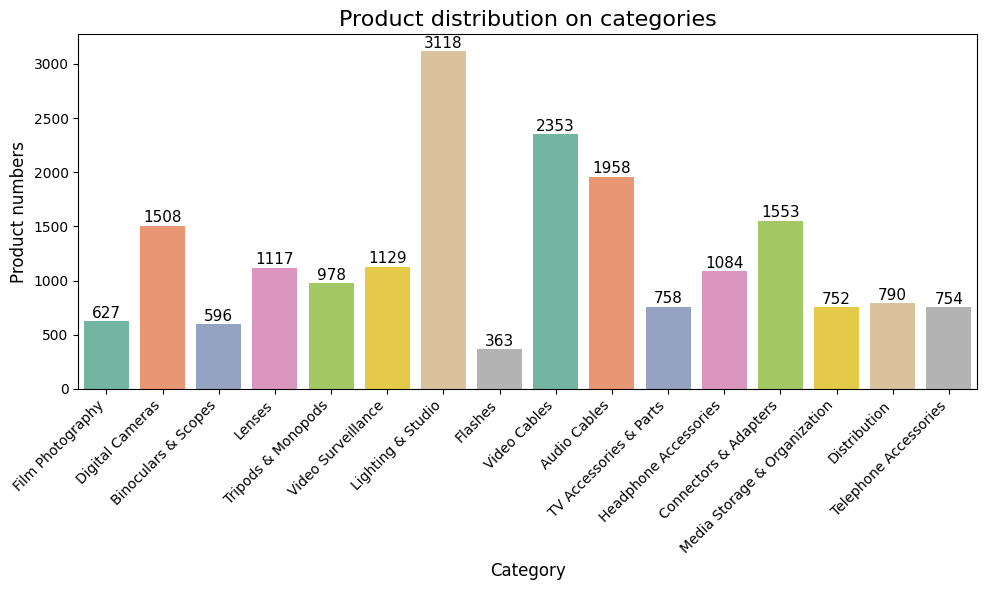

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

labels = data.y.numpy()
_, counts = np.unique(labels, return_counts=True)
class_names = []
with np.load(file_path) as loader:
    loader = dict(loader)
    class_names = loader['class_names']

plt.figure(figsize=(10, 6))
sns.barplot(x=class_names, y=counts, palette="Set2")
plt.title("Product distribution on categories", fontsize=16)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Product numbers", fontsize=12)

# Adăugăm valorile pe bare
for i, count in enumerate(counts):
    plt.text(i, count + max(counts)*0.01, str(count), ha='center', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.savefig('distributie_clase.png', dpi=300)
plt.show()

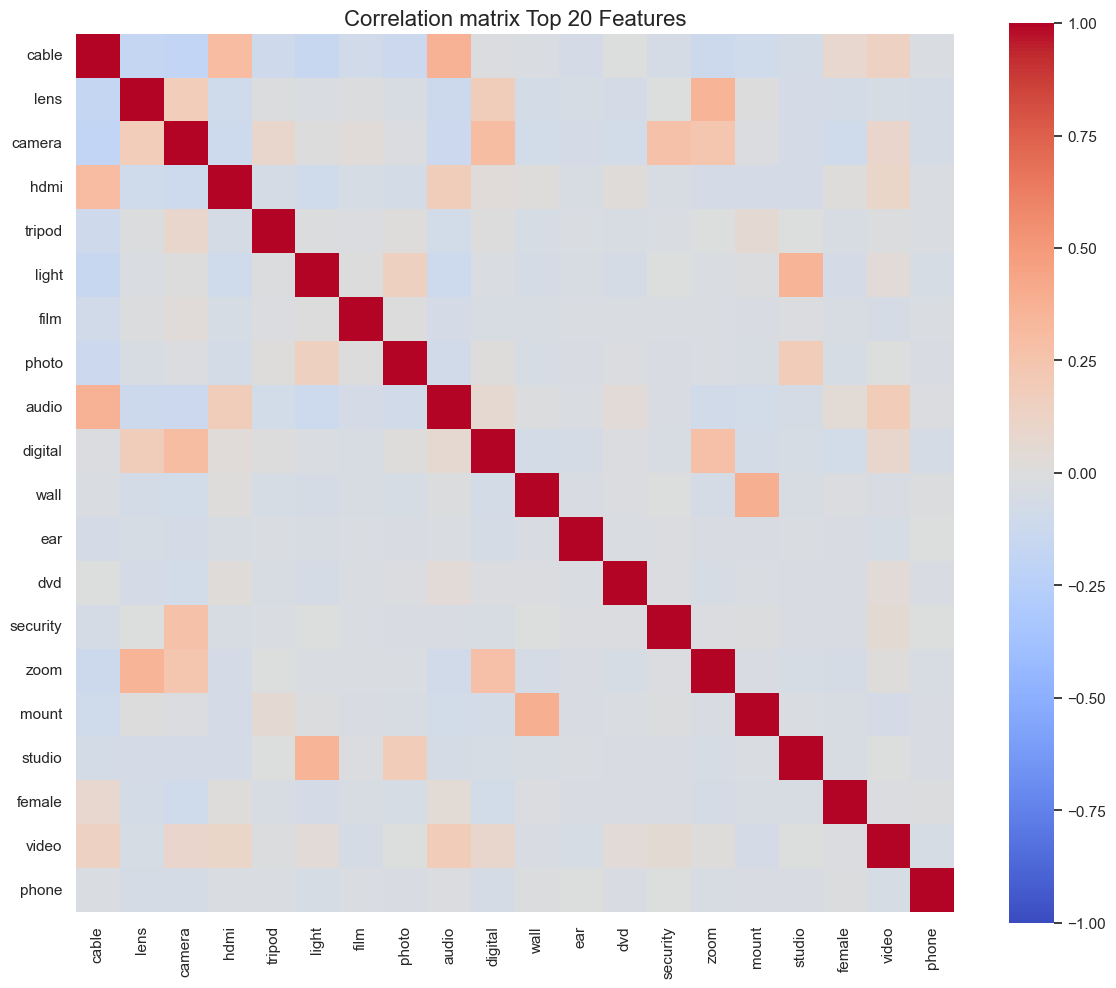

In [83]:
import pandas as pd

X_top_20 = data.x.numpy()[:, top_20_indices]

df_top20 = pd.DataFrame(X_top_20, columns=top_20_words)
corr_matrix = df_top20.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlation matrix Top 20 Features", fontsize=16)
plt.tight_layout()
plt.savefig('matrice_corelatie_top20.png', dpi=300)
plt.show()

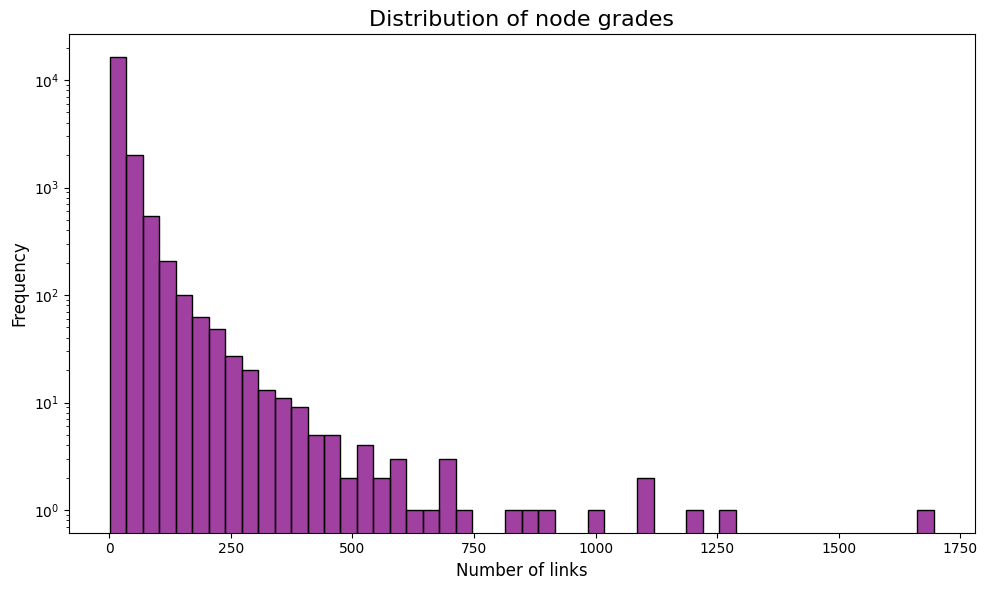

In [18]:
import networkx as nx
from torch_geometric.utils import to_networkx

G = to_networkx(data, to_undirected=True)

degrees = [d for n, d in G.degree()]

plt.figure(figsize=(10, 6))
sns.histplot(degrees, bins=50, kde=False, color='purple')
plt.title("Distribution of node grades", fontsize=16)
plt.xlabel("Number of links", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
# Setăm axa X pe scală logaritmică deoarece de obicei grafurile de achiziții au o coadă lungă (Power Law)
plt.yscale('log')
plt.tight_layout()
plt.savefig('distributie_grade.png', dpi=300)
plt.show()

Calculez t-SNE pentru datele brute (TF-IDF)...


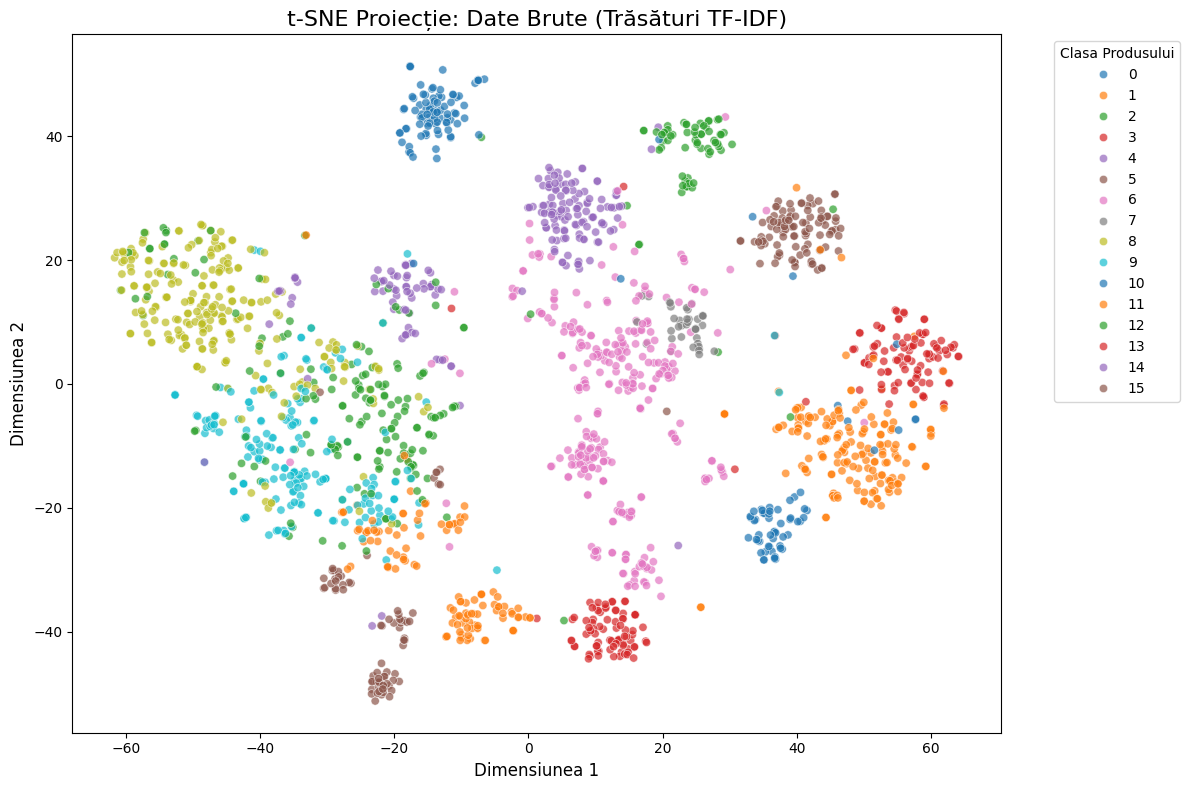

In [19]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Luăm un eșantion ca să nu aștepți o oră după t-SNE
sample_size = min(2000, data.x.shape[0])
indices_sample = np.random.choice(data.x.shape[0], sample_size, replace=False)

# Datele BRUTE
X_sample_before = data.x.numpy()[indices_sample]
y_sample = data.y.numpy()[indices_sample]

# 2. Calculăm t-SNE
print("Calculez t-SNE pentru datele brute (TF-IDF)...")
tsne_before = TSNE(n_components=2, random_state=42)
X_tsne_before = tsne_before.fit_transform(X_sample_before)

# 3. Desenăm un singur grafic curat
plt.figure(figsize=(12, 8))
palette = sns.color_palette("tab10", len(np.unique(y_sample)))

sns.scatterplot(
    x=X_tsne_before[:, 0], y=X_tsne_before[:, 1],
    hue=y_sample, palette=palette,
    legend='full',
    alpha=0.7
)

plt.title("t-SNE Proiecție: Date Brute (Trăsături TF-IDF)", fontsize=16)
plt.xlabel("Dimensiunea 1", fontsize=12)
plt.ylabel("Dimensiunea 2", fontsize=12)

# Mutăm legenda în afara graficului ca să nu acopere punctele
plt.legend(title='Clasa Produsului', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig('tsne_date_brute.png', dpi=300)
plt.show()

In [20]:
import typing
class GraphInfo:
    def __init__(self, edges: typing.Tuple[list, list], num_nodes: int):
        self.edges = edges
        self.num_nodes = num_nodes


In [21]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, ops
import typing


u, v = data.edge_index.numpy()

graph = GraphInfo(
    edges=(u.tolist(), v.tolist()),
    num_nodes=data.num_nodes
)

print(f"GraphInfo creat: {graph.num_nodes} noduri, {len(graph.edges[0])} muchii.")

GraphInfo creat: 19438 noduri, 387902 muchii.


In [22]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

class StrictGCNConv(layers.Layer):
    def __init__(self, in_feat, out_feat, graph_info, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.in_feat = in_feat
        self.out_feat = out_feat
        self.graph_info = graph_info

        self.weight = self.add_weight(
            initializer="glorot_uniform",
            shape=(in_feat, out_feat),
            dtype="float32",
            name="gcn_weight"
        )
        self.activation = layers.Activation(activation) if activation else None

    def call(self, features):
        # 1. Transformarea liniară
        h = tf.matmul(features, self.weight)

        source_nodes = tf.convert_to_tensor(self.graph_info.edges[0], dtype=tf.int32)
        target_nodes = tf.convert_to_tensor(self.graph_info.edges[1], dtype=tf.int32)
        num_nodes = tf.cast(self.graph_info.num_nodes, tf.int32)

        # 2. Adăugăm Self-Loops în siguranță
        self_loops = tf.range(num_nodes, dtype=tf.int32)
        source_nodes = tf.concat([source_nodes, self_loops], axis=0)
        target_nodes = tf.concat([target_nodes, self_loops], axis=0)

        # 3. Normalizarea Simetrică
        ones = tf.ones_like(source_nodes, dtype=tf.float32)
        deg = tf.math.unsorted_segment_sum(ones, target_nodes, num_segments=num_nodes)

        deg_inv_sqrt = tf.pow(deg, -0.5)
        deg_inv_sqrt = tf.where(tf.math.is_inf(deg_inv_sqrt), 0.0, deg_inv_sqrt)

        norm_source = tf.gather(deg_inv_sqrt, source_nodes)
        norm_target = tf.gather(deg_inv_sqrt, target_nodes)
        norm = norm_source * norm_target

        # 4. Propagarea Mesajelor
        h_source = tf.gather(h, source_nodes)
        h_normalized = h_source * tf.expand_dims(norm, -1)

        # 5. Agregarea finală
        aggregated = tf.math.unsorted_segment_sum(h_normalized, target_nodes, num_segments=num_nodes)

        return self.activation(aggregated) if self.activation else aggregated

In [23]:
class StrictGCNModel(layers.Layer):
    def __init__(self, in_feat, out_feat, num_classes, graph_info, dropout=0.0, **kwargs):
        super().__init__(**kwargs)

        # Primul strat GCN pur
        self.gcn1 = StrictGCNConv(in_feat, out_feat, graph_info, activation="relu")
        self.ln1 = layers.LayerNormalization()
        self.drop1 = layers.Dropout(dropout)

        # Al doilea strat GCN pur
        self.gcn2 = StrictGCNConv(out_feat, out_feat, graph_info, activation=None)
        self.ln2 = layers.LayerNormalization()
        self.drop2 = layers.Dropout(dropout)

        # Clasificarea finală
        self.dense = layers.Dense(num_classes, activation="softmax")

    def call(self, inputs, training=None):
        x = self.gcn1(inputs)
        x = self.ln1(x, training=training)
        x = self.drop1(x, training=training)

        x = self.gcn2(x)
        x = self.ln2(x, training=training)
        x = self.drop2(x, training=training)

        return self.dense(x)

In [24]:
import tensorflow as tf
import keras

def focal_loss_custom(gamma=2.0):
    """
    Focal Loss care returnează un vector per nod.
    Keras înmulțește fiecare element cu sample_weight înainte de a face media — corect matematic.
    """
    def loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)

        cross_entropy = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)

        y_true_casted = tf.cast(y_true, tf.int32)
        batch_size    = tf.shape(y_pred)[0]
        indices       = tf.stack([tf.range(batch_size), y_true_casted], axis=1)
        p_t           = tf.gather_nd(y_pred, indices)

        modulating_factor = tf.pow(1.0 - p_t, gamma)

        return modulating_factor * cross_entropy

    return loss_fn

In [25]:
import keras_tuner as kt

from sklearn.utils.class_weight import compute_class_weight

class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_input),
    y=y_input[data.train_mask.numpy().astype(bool)]
)
class_weights = np.power(class_weights_raw, 0.5)
class_weight_dict = dict(enumerate(class_weights))
print(class_weight_dict)

combined_weight = train_weight.copy()
for cls, weight in class_weight_dict.items():
    combined_weight[y_input == cls] *= weight

def build_tuned_model(hp):
    out_feat = hp.Choice("out_feat", [16, 32, 64])
    lr       = hp.Float("lr", 1e-4, 1e-3, sampling="log")
    dropout  = hp.Float("dropout", 0.0, 0.4, step=0.1)

    inputs  = keras.Input((num_features,))
    # Chemăm modelul Strict GCN
    outputs = StrictGCNModel(num_features, out_feat, 16, graph, dropout)(inputs)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=lr),
        loss      = focal_loss_custom(gamma=2.0), # Păstrăm Focal Loss-ul vectorizat
        weighted_metrics = ["accuracy"]
    )
    return model

import shutil
shutil.rmtree("tuning_amazon_fixed", ignore_errors=True)

tuner = kt.BayesianOptimization(
    build_tuned_model,
    objective  = "val_loss",
    max_trials = 20,
    directory  = "tuning_amazon_fixed",
    project_name = "hybrid_v2"
)

tuner.search(
    X_input, y_input,
    sample_weight     = combined_weight,
    validation_data   = (X_input, y_input, val_weight),
    epochs            = 30,
    batch_size        = len(X_input),
    callbacks         = [keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)

Trial 20 Complete [00h 00m 17s]
val_loss: 0.04935410991311073

Best val_loss So Far: 0.035151802003383636
Total elapsed time: 00h 05m 25s


Top 10 GCN tuning trials:


,trial_id,val_loss,out_feat,lr,dropout
11,11,0.035152,64,0.001000,0.2
9,09,0.036366,64,0.001000,0.0
14,14,0.037964,64,0.001000,0.0
12,12,0.038042,64,0.001000,0.1
16,16,0.038840,64,0.001000,0.0
17,17,0.039692,64,0.001000,0.4
0,00,0.042675,64,0.000577,0.1
15,15,0.043105,64,0.001000,0.3
10,10,0.044707,64,0.001000,0.4
18,18,0.045525,64,0.001000,0.4


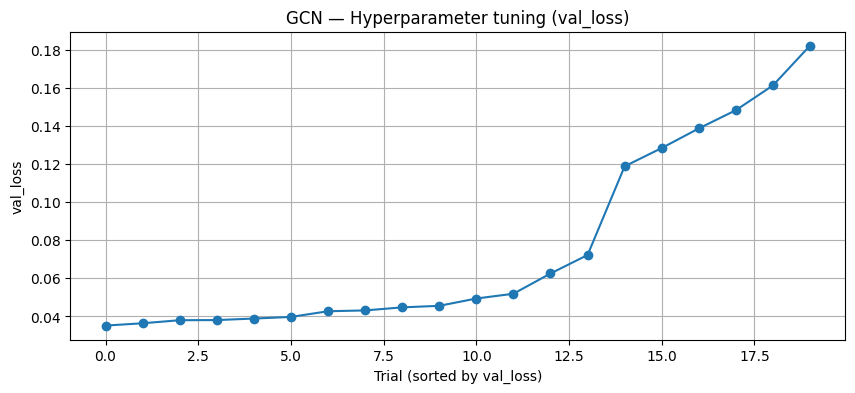

BEST GCN HP: {'out_feat': 64, 'lr': 0.001, 'dropout': 0.2}


In [26]:
rows = []
for t in tuner.oracle.trials.values():
    r = {"trial_id": t.trial_id, "val_loss": t.score}
    r.update(t.hyperparameters.values)
    rows.append(r)
gcn_tuning_df = pd.DataFrame(rows).sort_values("val_loss")

print("Top 10 GCN tuning trials:")
display(gcn_tuning_df.head(10))

plt.figure(figsize=(10,4))
plt.plot(gcn_tuning_df["val_loss"].values, marker="o")
plt.xlabel("Trial (sorted by val_loss)")
plt.ylabel("val_loss")
plt.title("GCN — Hyperparameter tuning (val_loss)")
plt.grid(True)
plt.show()

gcn_tuned = tuner.get_best_models(1)[0]
gcn_best_hp = tuner.get_best_hyperparameters(1)[0]
print("BEST GCN HP:", gcn_best_hp.values)


In [27]:
from sklearn import metrics as skmetrics

tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best hyperparameters:")
print(f"  out_feat:         {best_hp.get('out_feat')}")
print(f"  lr:               {best_hp.get('lr'):.6f}")
print(f"  dropout:          {best_hp.get('dropout')}")

best_model = tuner.hypermodel.build(best_hp)

best_model.fit(
    X_input, y_input,
    validation_data = (X_input, y_input, val_weight),
    sample_weight = combined_weight,
    batch_size    = len(X_input),
    epochs        = 100,
    callbacks     = [keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)]
)

Best hyperparameters:
  out_feat:         64
  lr:               0.001000
  dropout:          0.2
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.0749 - loss: 2.1221 - val_accuracy: 0.1229 - val_loss: 0.2501
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.0700 - loss: 1.8963 - val_accuracy: 0.2047 - val_loss: 0.2136
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.0889 - loss: 1.8138 - val_accuracy: 0.2881 - val_loss: 0.1841
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.1031 - loss: 1.7344 - val_accuracy: 0.3683 - val_loss: 0.1616
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.1172 - loss: 1.6627 - val_accuracy: 0.4388 - val_loss: 0.1454
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.1306 - loss: 1.6210 - val_accuracy: 0.4743 - val_loss: 0.1331
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - accuracy: 0.1435 - loss: 1.5803 - val_accuracy: 0.5093 - val_loss: 0.1223
Epoch 8/100
1/1 

In [28]:
y_pred      = np.argmax(best_model.predict(X_input, batch_size=len(X_input)), axis=1)
test_mask   = data.test_mask.numpy().astype(bool)
y_pred_test = y_pred[test_mask]
y_true_test = y_input[test_mask]

print("Test set results:",
      "accu= {:.2f}".format(skmetrics.accuracy_score(y_true_test, y_pred_test) * 100),
      "macro_p= {:.2f}".format(skmetrics.precision_score(y_true_test, y_pred_test, average='macro') * 100),
      "macro_r= {:.2f}".format(skmetrics.recall_score(y_true_test, y_pred_test, average='macro') * 100),
      "macro_f1= {:.2f}".format(skmetrics.f1_score(y_true_test, y_pred_test, average='macro') * 100),
      "micro_f1= {:.2f}".format(skmetrics.f1_score(y_true_test, y_pred_test, average='micro') * 100))
print(skmetrics.classification_report(y_true_test, y_pred_test, digits=4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Test set results: accu= 82.92 macro_p= 83.34 macro_r= 83.42 macro_f1= 83.10 micro_f1= 82.92
              precision    recall  f1-score   support

           0     0.8824    0.9574    0.9184       141
           1     0.8703    0.7482    0.8046       278
           2     0.9483    0.9402    0.9442       117
           3     0.6795    0.9217    0.7823       230
           4     0.8507    0.8744    0.8624       215
           5     0.9121    0.9776    0.9437       223
           6     0.9528    0.8940    0.9224       632
           7     0.5857    0.5190    0.5503        79
           8     0.7901    0.7870    0.7885       507
           9     0.6864    0.7864    0.7330       398
          10     0.9489    0.8784    0.9123       148
          11     0.8789    0.8520    0.8653       196
          12     0.7131    0.5578    0.6259       303
          13     0.9371    0.9853    0.9606       136
          14     0.7571    0.6974    0.7260       152
       

In [29]:
import keras_tuner as kt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import shutil
import os

X_train_mlp = data.x[data.train_mask].numpy()
y_train_mlp = data.y[data.train_mask].numpy()

X_test_mlp = data.x[data.test_mask].numpy()
y_test_mlp = data.y[data.test_mask].numpy()

X_val_mlp = data.x[data.val_mask].numpy()
y_val_mlp = data.y[data.val_mask].numpy()

input_dim = X_train_mlp.shape[1]
num_classes = 16
folder_tuner = 'tuner_mlp_amazon'

if os.path.exists(folder_tuner):
    shutil.rmtree(folder_tuner)

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_input),
    y=y_input[data.train_mask.numpy().astype(bool)]
)
class_weights = np.power(class_weights_raw, 0.5)
class_weight_dict = dict(enumerate(class_weights))

def build_tuned_mlp(hp):
    model = keras.Sequential()
    model.add(layers.InputLayer(input_shape=(input_dim,)))

    hp_units1 = hp.Int('units_1', min_value=64, max_value=256, step=64)
    model.add(layers.Dense(units=hp_units1, activation='relu'))

    hp_drop1 = hp.Float('dropout_1', min_value=0.2, max_value=0.6, step=0.1)
    model.add(layers.Dropout(rate=hp_drop1))

    hp_units2 = hp.Int('units_2', min_value=32, max_value=128, step=32)
    model.add(layers.Dense(units=hp_units2, activation='relu'))

    hp_drop2 = hp.Float('dropout_2', min_value=0.1, max_value=0.5, step=0.1)
    model.add(layers.Dropout(rate=hp_drop2))

    model.add(layers.Dense(num_classes, activation='softmax'))

    hp_lr = hp.Choice('learning_rate', values=[1e-2, 5e-3, 1e-3])

    model.compile(
        optimizer        = keras.optimizers.Adam(learning_rate=hp_lr),
        loss             = focal_loss_custom(gamma=2.0),  # same as GNNs
        weighted_metrics = ["accuracy"]                   # same as GNNs
    )
    return model

tuner_mlp = kt.BayesianOptimization(
    build_tuned_mlp,
    objective    = 'val_loss',        # same as GNNs, not val_accuracy
    max_trials   = 20,
    directory    = folder_tuner,
    project_name = 'mlp_baseline'
)

tuner_mlp.search(
    X_train_mlp, y_train_mlp,
    epochs            = 30,
    validation_data   = (X_val_mlp, y_val_mlp),
    class_weight      = class_weight_dict,   # balancing via class_weight for MLP
    callbacks         = [keras.callbacks.EarlyStopping(
                            monitor='val_loss', patience=5, restore_best_weights=True)]
)

best_hps_mlp = tuner_mlp.get_best_hyperparameters(num_trials=1)[0]
print(f"\n--- CEI MAI BUNI PARAMETRI GASITI ---")
print(f"Neuroni strat 1: {best_hps_mlp.get('units_1')}")
print(f"Dropout strat 1: {best_hps_mlp.get('dropout_1')}")
print(f"Neuroni strat 2: {best_hps_mlp.get('units_2')}")
print(f"Dropout strat 2: {best_hps_mlp.get('dropout_2')}")
print(f"Learning Rate:   {best_hps_mlp.get('learning_rate')}")

best_mlp_model = tuner_mlp.hypermodel.build(best_hps_mlp)

history_best_mlp = best_mlp_model.fit(
    X_train_mlp, y_train_mlp,
    epochs          = 100,
    validation_data = (X_val_mlp, y_val_mlp),
    class_weight    = class_weight_dict,
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_loss', patience=10, restore_best_weights=True)]
)

from sklearn.metrics import classification_report

y_pred_mlp = best_mlp_model.predict(X_test_mlp).argmax(axis=1)

print("\n=== REZULTATE FINALE MLP BASELINE ===")
print(classification_report(y_test_mlp, y_pred_mlp, digits=4))

Trial 20 Complete [00h 00m 17s]
val_loss: 0.16201624274253845

Best val_loss So Far: 0.1593625545501709
Total elapsed time: 00h 05m 10s

--- CEI MAI BUNI PARAMETRI GASITI ---
Neuroni strat 1: 128
Dropout strat 1: 0.30000000000000004
Neuroni strat 2: 64
Dropout strat 2: 0.2
Learning Rate:   0.001
Epoch 1/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7250 - loss: 0.6080 - val_accuracy: 0.8709 - val_loss: 0.2232
Epoch 2/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8618 - loss: 0.2265 - val_accuracy: 0.8853 - val_loss: 0.1908
Epoch 3/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8768 - loss: 0.1926 - val_accuracy: 0.8853 - val_loss: 0.1837
Epoch 4/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8877 - loss: 0.1700 - val_accuracy: 0.8889 - val_loss: 0.1750
Epoch 5/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8913 - loss: 0.1530 - val_accuracy: 0.8909 - val_loss: 0.1752
Epoch 6/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc

In [30]:
import numpy as np
import tensorflow as tf

X_full = data.x.numpy()
y_full = data.y.numpy()

num_nodes = X_full.shape[0]
self_loops = np.vstack((np.arange(num_nodes), np.arange(num_nodes)))
edges_with_loops = np.hstack((data.edge_index.numpy(), self_loops))

edge_index_tf = tf.convert_to_tensor(edges_with_loops, dtype=tf.int32)

input_dim = X_full.shape[1]
num_classes = 16

train_mask = data.train_mask.numpy().astype(bool)
val_mask   = data.val_mask.numpy().astype(bool)
test_mask  = data.test_mask.numpy().astype(bool)

train_weights = np.zeros(X_full.shape[0])
train_weights[train_mask] = 1.0

val_weights = np.zeros(X_full.shape[0])
val_weights[val_mask] = 1.0

print(f"Date pregătite! Graful are acum {edge_index_tf.shape[1]} muchii (inclusiv self-loops).")

Date pregătite! Graful are acum 407340 muchii (inclusiv self-loops).


In [31]:
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

class StaticGraphAttn(layers.Layer):
    """ Un singur cap de atenție (GAT) 100% fidel lucrării originale """
    def __init__(self, in_feat, out_feat, edge_index, dropout_rate=0.0, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.edge_index = edge_index

        self.W = self.add_weight(shape=(in_feat, out_feat), initializer="glorot_uniform", trainable=True, name="W")
        self.a = self.add_weight(shape=(2 * out_feat, 1), initializer="glorot_uniform", trainable=True, name="a")

        self.leaky = layers.LeakyReLU(0.2)
        # 👉 MODIFICARE VITALĂ: GAT aplică dropout pe atenția în sine!
        self.attn_dropout = layers.Dropout(dropout_rate)
        self.activation = layers.Activation(activation) if activation else None

    def call(self, features, training=None):
        src = self.edge_index[0]
        dst = self.edge_index[1]
        N = tf.shape(features)[0]

        # 1. Transformare liniară
        h = tf.matmul(features, self.W)

        # 2. Colectăm la capetele muchiilor
        h_i = tf.gather(h, dst)
        h_j = tf.gather(h, src)

        # 3. Coeficienți ne-normalizați
        e = tf.squeeze(tf.matmul(tf.concat([h_i, h_j], axis=-1), self.a), axis=-1)
        e = self.leaky(e)

        # 4. Softmax stabil
        max_e = tf.math.unsorted_segment_max(e, dst, N)
        max_e_edges = tf.gather(max_e, dst)
        exp_e = tf.exp(e - max_e_edges)
        sum_exp = tf.math.unsorted_segment_sum(exp_e, dst, N)
        alpha = exp_e / (tf.gather(sum_exp, dst) + 1e-9)

        # 👉 MODIFICARE VITALĂ: Aplicăm Dropout pe coeficienții de atenție
        alpha = self.attn_dropout(alpha, training=training)

        # 5. Agregare
        messages = tf.expand_dims(alpha, -1) * h_j
        out = tf.math.unsorted_segment_sum(messages, dst, N)

        return self.activation(out) if self.activation else out

In [32]:
class MultiHeadStaticGAT(layers.Layer):
    """ GAT Multi-Head care trimite parametrul de training mai departe """
    def __init__(self, num_heads, in_feat, out_feat, edge_index, dropout_rate=0.0, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.heads = [
            # Acum trimitem dropout_rate și în interiorul capetelor de atenție
            StaticGraphAttn(in_feat, out_feat, edge_index, dropout_rate=dropout_rate, activation=activation)
            for _ in range(num_heads)
        ]
        # Păstrăm și un dropout pe vectorul final concatenat
        self.feature_dropout = layers.Dropout(dropout_rate)

    def call(self, features, training=None):
        # 👉 VITAL: Pasează parametrul `training` mai departe către capetele de atenție!
        head_outputs = [head(features, training=training) for head in self.heads]

        x = tf.concat(head_outputs, axis=-1)
        x = self.feature_dropout(x, training=training)

        return x

In [33]:

tf.random.set_seed(42)

def build_tuned_gat(hp):
    hp_heads = hp.Choice("num_heads", [2, 4, 8])
    hp_out_feat = hp.Choice("out_feat", [8, 16, 32])
    hp_lr = hp.Float("lr", min_value=1e-4, max_value=5e-3, sampling="log")
    hp_dropout = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = keras.Sequential()
    model.add(layers.InputLayer(input_shape=(input_dim,)))

    model.add(MultiHeadStaticGAT(
        num_heads=hp_heads,
        in_feat=input_dim,
        out_feat=hp_out_feat,
        edge_index=edge_index_tf,
        dropout_rate=hp_dropout,
        activation='relu'
    ))
    model.add(StaticGraphAttn(in_feat=hp_heads*hp_out_feat, out_feat=hp_out_feat, 
                          edge_index=edge_index_tf, dropout_rate=hp_dropout, activation=None))

    model.add(layers.Dense(num_classes, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_lr),
        loss=focal_loss_custom(gamma=2.0),
        weighted_metrics=["accuracy"]
    )

    return model


In [34]:
import os
import shutil
import pandas as pd
import keras_tuner as kt
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report


y_train_only = y_full[train_mask]

class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_only),
    y=y_train_only
)
class_weights = np.power(class_weights_raw, 0.5)
class_weight_dict = dict(enumerate(class_weights))

print("\n--- Greutăți aplicate pentru GAT ---")
for cls, w in class_weight_dict.items():
    print(f"Clasa {cls}: {w:.2f}")

# Creăm un vector nou de greutăți: înmulțim masca de 1.0 cu greutatea clasei
train_weights_balanced = train_weights.copy()
for cls, weight in class_weight_dict.items():
    train_weights_balanced[y_full == cls] *= weight

folder_tuner_gat = 'tuner_gat_amazon'
if os.path.exists(folder_tuner_gat):
    shutil.rmtree(folder_tuner_gat)

tuner_gat = kt.BayesianOptimization(
    build_tuned_gat,
    objective='val_loss',
    max_trials=20,
    directory=folder_tuner_gat,
    project_name='gat_amazon'
)

print("\nÎncepem căutarea Bayesiană pentru modelul GAT...")

tuner_gat.search(
    X_full, y_full,
    sample_weight=train_weights_balanced,
    epochs=30,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_full, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
)


best_hps_gat = tuner_gat.get_best_hyperparameters(num_trials=1)[0]
print(f"\n--- CEI MAI BUNI PARAMETRI GAT GASIȚI ---")
print(f"Număr Capete (Heads): {best_hps_gat.get('num_heads')}")
print(f"Features per Capăt: {best_hps_gat.get('out_feat')}")
print(f"Rata Dropout: {best_hps_gat.get('dropout')}")
print(f"Learning Rate: {best_hps_gat.get('lr'):.6f}")

best_gat_model = tuner_gat.hypermodel.build(best_hps_gat)

history_best_gat = best_gat_model.fit(
    X_full, y_full,
    sample_weight=train_weights_balanced,
    epochs=150,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_full, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
)


Trial 20 Complete [00h 00m 27s]
val_loss: 0.046212486922740936

Best val_loss So Far: 0.0343497171998024
Total elapsed time: 00h 08m 07s

--- CEI MAI BUNI PARAMETRI GAT GASIȚI ---
Număr Capete (Heads): 8
Features per Capăt: 32
Rata Dropout: 0.4
Learning Rate: 0.005000
Epoch 1/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.0403 - loss: 1.6460 - val_accuracy: 0.5113 - val_loss: 0.2233
Epoch 2/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 940ms/step - accuracy: 0.4239 - loss: 1.5204 - val_accuracy: 0.5273 - val_loss: 0.2008
Epoch 3/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 949ms/step - accuracy: 0.4483 - loss: 1.3842 - val_accuracy: 0.5324 - val_loss: 0.1739
Epoch 4/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 940ms/step - accuracy: 0.4540 - loss: 1.2261 - val_accuracy: 0.5406 - val_loss: 0.1464
Epoch 5/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 932ms/step - accuracy: 0.4650 - loss: 1.0742 - val_accuracy: 0.5741 - val_loss: 0.1217
Epoch 6/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 934ms/step - accuracy: 0.5105 - loss: 0.9221 - val_accuracy

Top 10 GAT tuning trials:


,trial_id,val_loss,num_heads,out_feat,lr,dropout
13,13,0.034350,8,32,0.005000,0.4
15,15,0.034815,8,32,0.005000,0.2
12,12,0.034988,8,32,0.005000,0.0
14,14,0.035593,4,32,0.005000,0.2
17,17,0.036279,2,32,0.005000,0.4
18,18,0.036563,2,32,0.005000,0.0
19,19,0.046212,8,8,0.005000,0.0
1,01,0.050837,8,32,0.001348,0.1
11,11,0.057076,8,16,0.002104,0.0
10,10,0.071769,4,8,0.004630,0.3


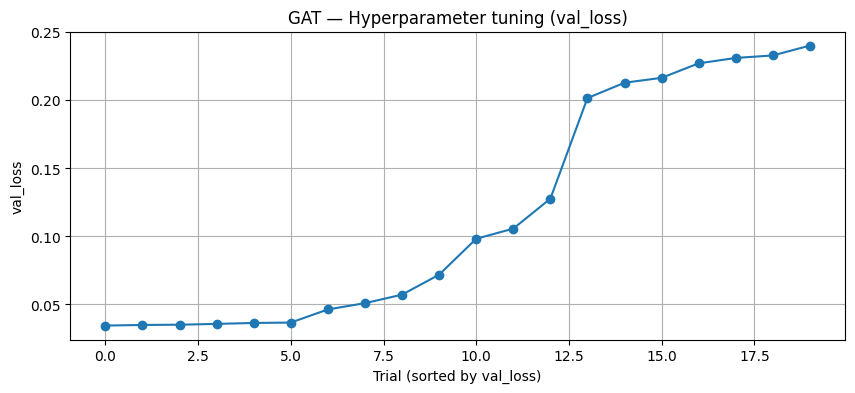

BEST GAT HP: {'num_heads': 8, 'out_feat': 32, 'lr': 0.005, 'dropout': 0.4}


In [35]:
rows = []
for t in tuner_gat.oracle.trials.values():
    r = {"trial_id": t.trial_id, "val_loss": t.score}
    r.update(t.hyperparameters.values)
    rows.append(r)
gat_tuning_df = pd.DataFrame(rows).sort_values("val_loss")

print("Top 10 GAT tuning trials:")
display(gat_tuning_df.head(10))

plt.figure(figsize=(10,4))
plt.plot(gat_tuning_df["val_loss"].values, marker="o")
plt.xlabel("Trial (sorted by val_loss)")
plt.ylabel("val_loss")
plt.title("GAT — Hyperparameter tuning (val_loss)")
plt.grid(True)
plt.show()

gat_best_hp = tuner_gat.get_best_hyperparameters(1)[0]
print("BEST GAT HP:", gat_best_hp.values)

In [36]:
from sklearn.metrics import classification_report
from sklearn import metrics as skmetrics

y_pred_probs_gat = best_gat_model.predict(X_full, batch_size=X_full.shape[0])
y_pred_gat_full = y_pred_probs_gat.argmax(axis=1)

y_test_true = y_full[test_mask]
y_test_pred = y_pred_gat_full[test_mask]

print("Test set results:",
      "accu= {:.2f}".format(skmetrics.accuracy_score(y_test_true, y_test_pred) * 100),
      "macro_p= {:.2f}".format(skmetrics.precision_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_r= {:.2f}".format(skmetrics.recall_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='macro') * 100),
      "micro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='micro') * 100))

print("\n=== REZULTATE FINALE GAT BAYESIAN (TEST SET) ===")
print(classification_report(y_test_true, y_test_pred, digits=4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 898ms/step
Test set results: accu= 84.23 macro_p= 84.52 macro_r= 84.47 macro_f1= 84.42 micro_f1= 84.23

=== REZULTATE FINALE GAT BAYESIAN (TEST SET) ===
              precision    recall  f1-score   support

           0     0.9291    0.9291    0.9291       141
           1     0.8261    0.8885    0.8562       278
           2     0.9561    0.9316    0.9437       117
           3     0.8341    0.7870    0.8098       230
           4     0.8354    0.9209    0.8761       215
           5     0.9643    0.9686    0.9664       223
           6     0.9434    0.9225    0.9328       632
           7     0.5412    0.5823    0.5610        79
           8     0.7827    0.8028    0.7926       507
           9     0.7283    0.7814    0.7539       398
          10     0.9296    0.8919    0.9103       148
          11     0.8653    0.8520    0.8586       196
          12     0.6758    0.5710    0.6190       303
          13     0.9853    0.9853    0.9853       136
        

In [37]:
import numpy as np
import tensorflow as tf

X_full = data.x.numpy()
y_full = data.y.numpy()

edge_index_tf = tf.convert_to_tensor(data.edge_index.numpy(), dtype=tf.int32)

input_dim = X_full.shape[1]
num_classes = 16

train_mask = data.train_mask.numpy().astype(bool)
val_mask   = data.val_mask.numpy().astype(bool)
test_mask  = data.test_mask.numpy().astype(bool)

train_weights = np.zeros(X_full.shape[0])
train_weights[train_mask] = 1.0

val_weights = np.zeros(X_full.shape[0])
val_weights[val_mask] = 1.0

X_train_inductive = X_full.copy()
mask_not_train = ~train_mask
X_train_inductive[mask_not_train] = 0.0

print(f"Date pregătite pentru GraphSAGE! Graful are {edge_index_tf.shape[1]} muchii.")
print(f"Am ascuns (zero features) pentru {np.sum(mask_not_train)} noduri pentru a testa generalizarea inductivă.")
# ------------------------------------------------------------------

Date pregătite pentru GraphSAGE! Graful are 387902 muchii.
Am ascuns (zero features) pentru 5832 noduri pentru a testa generalizarea inductivă.


In [38]:
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

class SAGEConvLayer(layers.Layer):
    def __init__(self, out_feat, edge_index, normalize=True, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.out_feat   = out_feat
        self.edge_index = edge_index
        self.normalize  = normalize

        self.W          = layers.Dense(out_feat, use_bias=False, kernel_initializer="glorot_uniform")
        self.activation = layers.Activation(activation) if activation else None

    def call(self, features, training=None):
        src       = self.edge_index[0]
        dst       = self.edge_index[1]
        num_nodes = tf.shape(features)[0]

        neighbor_features    = tf.gather(features, src)
        aggregated_neighbors = tf.math.unsorted_segment_mean(
            neighbor_features, dst, num_segments=num_nodes
        )

        combined = tf.concat([features, aggregated_neighbors], axis=-1)
        out      = self.W(combined)

        if self.activation:
            out = self.activation(out)
        if self.normalize:
            out = tf.math.l2_normalize(out, axis=-1)

        return out

In [39]:
class StaticGraphSAGE(layers.Layer):
    def __init__(self, out_feat, edge_index, dropout_rate=0.0, normalize=True, **kwargs):
        super().__init__(**kwargs)
        self.conv1 = SAGEConvLayer(out_feat, edge_index, normalize=normalize, activation='relu')
        self.conv2 = SAGEConvLayer(out_feat, edge_index, normalize=normalize, activation='relu')

        self.drop1 = layers.Dropout(dropout_rate)
        self.drop2 = layers.Dropout(dropout_rate)

    def call(self, features, training=None):
        x = self.drop1(features, training=training)
        x = self.conv1(x, training=training)
        x = self.drop2(x, training=training)
        x = self.conv2(x, training=training)
        return x

In [40]:
import os
import shutil
import pandas as pd

tf.random.set_seed(42)

def build_tuned_sage(hp):
    hp_out_feat = hp.Choice("out_feat", [16, 32, 64])
    hp_lr = hp.Float("lr", min_value=1e-4, max_value=5e-3, sampling="log")
    hp_dropout = hp.Float("dropout", 0.0, 0.5, step=0.1)

    hp_normalize = hp.Boolean("normalize", default=True)

    model = keras.Sequential()
    model.add(layers.InputLayer(input_shape=(input_dim,)))

    model.add(StaticGraphSAGE(
        out_feat=hp_out_feat,
        edge_index=edge_index_tf,
        dropout_rate=hp_dropout,
        normalize=hp_normalize
    ))

    model.add(layers.Dense(num_classes, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_lr),
        loss=focal_loss_custom(gamma=2.0),
        weighted_metrics=["accuracy"]
    )
    return model


folder_tuner_sage = 'tuner_sage_amazon'
if os.path.exists(folder_tuner_sage):
    shutil.rmtree(folder_tuner_sage)

y_train_only = y_full[train_mask]
class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_only),
    y=y_train_only
)
class_weights = np.power(class_weights_raw, 0.5) # 👉 VITAL
class_weight_dict = dict(enumerate(class_weights))

print("\n--- Greutăți aplicate pentru GraphSage ---")
for cls, w in class_weight_dict.items():
    print(f"Clasa {cls}: {w:.2f}")

train_weights_balanced = train_weights.copy()
for cls, weight in class_weight_dict.items():
    train_weights_balanced[y_full == cls] *= weight

tuner_sage = kt.BayesianOptimization(
    build_tuned_sage,
    objective='val_loss',
    max_trials=20,
    directory=folder_tuner_sage,
    project_name='sage_amazon'
)

tuner_sage.search(
    X_train_inductive, y_full,
    sample_weight=train_weights_balanced,
    epochs=30,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_train_inductive, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
)


best_hps_sage = tuner_sage.get_best_hyperparameters(num_trials=1)[0]
print(f"\n--- CEI MAI BUNI PARAMETRI GraphSAGE GASIȚI ---")
print(f"Features: {best_hps_sage.get('out_feat')}")
print(f"Rata Dropout: {best_hps_sage.get('dropout')}")
print(f"Normalize L2: {best_hps_sage.get('normalize')}")
print(f"Learning Rate: {best_hps_sage.get('lr'):.6f}")

best_sage_model = tuner_sage.hypermodel.build(best_hps_sage)

history_best_sage = best_sage_model.fit(
    X_train_inductive, y_full,
    sample_weight=train_weights_balanced,
    epochs=150,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_train_inductive, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
)

Trial 20 Complete [00h 00m 16s]
val_loss: 0.052786845713853836

Best val_loss So Far: 0.05132323130965233
Total elapsed time: 00h 06m 01s

--- CEI MAI BUNI PARAMETRI GraphSAGE GASIȚI ---
Features: 64
Rata Dropout: 0.4
Normalize L2: False
Learning Rate: 0.005000
Epoch 1/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0587 - loss: 1.6486 - val_accuracy: 0.4450 - val_loss: 0.2396
Epoch 2/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.3631 - loss: 1.6014 - val_accuracy: 0.5031 - val_loss: 0.2317
Epoch 3/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.4472 - loss: 1.5203 - val_accuracy: 0.4918 - val_loss: 0.2196
Epoch 4/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step - accuracy: 0.4548 - loss: 1.4019 - val_accuracy: 0.4743 - val_loss: 0.2030
Epoch 5/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.4447 - loss: 1.2553 - val_accuracy: 0.4794 - val_loss: 0.1831
Epoch 6/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.4442 - loss: 1.0935 - val_accuracy: 0.535

Top 10 SAGE tuning trials:


,trial_id,val_loss,out_feat,lr,dropout,normalize
12,12,0.051323,64,0.005000,0.4,False
17,17,0.051632,64,0.005000,0.4,False
18,18,0.052741,64,0.005000,0.4,False
19,19,0.052787,64,0.005000,0.4,False
16,16,0.052937,64,0.005000,0.4,False
15,15,0.054321,64,0.005000,0.4,False
13,13,0.054850,64,0.005000,0.3,False
5,05,0.075937,64,0.001890,0.3,False
14,14,0.114583,64,0.005000,0.4,True
11,11,0.187286,16,0.002304,0.3,True


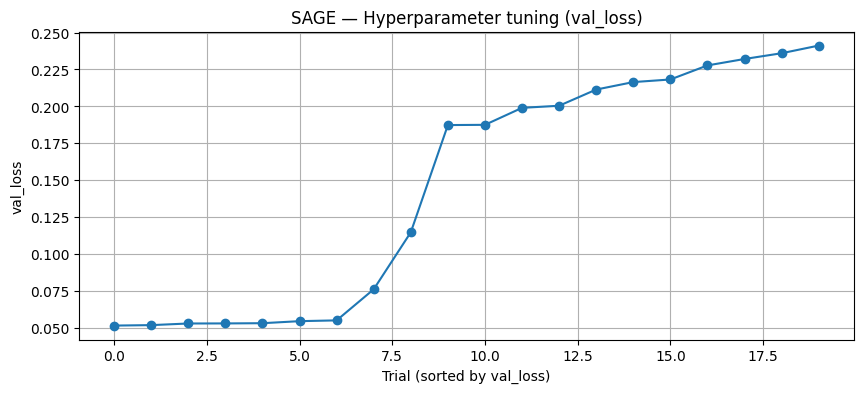

BEST SAGE HP: {'out_feat': 64, 'lr': 0.005, 'dropout': 0.4, 'normalize': False}


In [41]:
rows = []
for t in tuner_sage.oracle.trials.values():
    r = {"trial_id": t.trial_id, "val_loss": t.score}
    r.update(t.hyperparameters.values)
    rows.append(r)
sage_tuning_df = pd.DataFrame(rows).sort_values("val_loss")

print("Top 10 SAGE tuning trials:")
display(sage_tuning_df.head(10))

plt.figure(figsize=(10,4))
plt.plot(sage_tuning_df["val_loss"].values, marker="o")
plt.xlabel("Trial (sorted by val_loss)")
plt.ylabel("val_loss")
plt.title("SAGE — Hyperparameter tuning (val_loss)")
plt.grid(True)
plt.show()

sage_tuned = tuner_sage.get_best_models(1)[0]
sage_best_hp = tuner_sage.get_best_hyperparameters(1)[0]
print("BEST SAGE HP:", sage_best_hp.values)

In [42]:
from sklearn import metrics as skmetrics
from sklearn.metrics import classification_report

y_pred_probs_sage = best_sage_model.predict(X_full, batch_size=X_full.shape[0])
y_pred_sage_full = y_pred_probs_sage.argmax(axis=1)

y_test_true = y_full[test_mask]
y_test_pred = y_pred_sage_full[test_mask]

print("Test set results:",
      "accu= {:.2f}".format(skmetrics.accuracy_score(y_test_true, y_test_pred) * 100),
      "macro_p= {:.2f}".format(skmetrics.precision_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_r= {:.2f}".format(skmetrics.recall_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='macro') * 100),
      "micro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='micro') * 100))

print("\n=== REZULTATE FINALE GraphSage (TEST SET) ===")
print(classification_report(y_test_true, y_test_pred, digits=4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step
Test set results: accu= 84.16 macro_p= 85.00 macro_r= 84.12 macro_f1= 84.37 micro_f1= 84.16

=== REZULTATE FINALE GraphSage (TEST SET) ===
              precision    recall  f1-score   support

           0     0.8993    0.9504    0.9241       141
           1     0.8279    0.9173    0.8703       278
           2     0.9474    0.9231    0.9351       117
           3     0.8879    0.8609    0.8742       230
           4     0.7912    0.9163    0.8491       215
           5     0.9731    0.9731    0.9731       223
           6     0.9517    0.9051    0.9278       632
           7     0.6774    0.5316    0.5957        79
           8     0.7711    0.8304    0.7996       507
           9     0.6970    0.7513    0.7231       398
          10     0.9559    0.8784    0.9155       148
          11     0.8291    0.8418    0.8354       196
          12     0.7042    0.5578    0.6225       303
          13     0.9852    0.9779    0.9815       136
          1

# **LINK PREDICTION**

In [43]:
import torch_geometric.transforms as T

# Folosim un transformator care face split-ul automat pentru Link Prediction
# Va tăia 10% din muchii pentru validare și 10% pentru test
# add_negative_train_samples=True va genera automat muchii false (etichetate cu 0)

link_split = T.RandomLinkSplit(
    num_val=0.1,
    num_test=0.1,
    is_undirected=True,
    add_negative_train_samples=True,
    disjoint_train_ratio=0.0,
    neg_sampling_ratio=1.0
)

# Aplicăm pe datele noastre
train_data, val_data, test_data = link_split(data)

print("=== SPLIT PENTRU LINK PREDICTION ===")
print(f"Muchii pentru Antrenament (Reale + False): {train_data.edge_label_index.shape[1]}")
print(f"Muchii pentru Validare (Reale + False): {val_data.edge_label_index.shape[1]}")
print(f"Muchii pentru Testare (Reale + False): {test_data.edge_label_index.shape[1]}")

# Să ne uităm la ce conține efectiv antrenamentul:
print("\nStructura noului 'train_data':")
print("- edge_index (Muchiile folosite DOAR pentru a transmite mesaje):", train_data.edge_index.shape)
print("- edge_label_index (Perechile de noduri pe care modelul e testat):", train_data.edge_label_index.shape)
print("- edge_label (Etichetele 1=Muchi reală, 0=Muchie falsă):", train_data.edge_label.shape)

=== SPLIT PENTRU LINK PREDICTION ===
Muchii pentru Antrenament (Reale + False): 310322
Muchii pentru Validare (Reale + False): 38790
Muchii pentru Testare (Reale + False): 38790

Structura noului 'train_data':
- edge_index (Muchiile folosite DOAR pentru a transmite mesaje): torch.Size([2, 310322])
- edge_label_index (Perechile de noduri pe care modelul e testat): torch.Size([2, 310322])
- edge_label (Etichetele 1=Muchi reală, 0=Muchie falsă): torch.Size([310322])


In [44]:
import tensorflow as tf

# Convertim muchiile de antrenament
edge_index_train_np = train_data.edge_index.numpy()

# ✅ FIX: Symmetrize train edges (PyG RandomLinkSplit with is_undirected=True
# stores only one direction in edge_index for message passing)
src, dst = edge_index_train_np[0], edge_index_train_np[1]
sym_src = np.concatenate([src, dst])
sym_dst = np.concatenate([dst, src])
# Remove duplicates
sym_edges = np.unique(np.stack([sym_src, sym_dst], axis=0), axis=1)
edge_index_train_tf = tf.convert_to_tensor(sym_edges, dtype=tf.int32)

edge_label_index_train_tf = tf.convert_to_tensor(train_data.edge_label_index.numpy(), dtype=tf.int32)
y_train_link = tf.convert_to_tensor(train_data.edge_label.numpy(), dtype=tf.float32)

# Convertim muchiile de validare (pentru a opri antrenamentul la timp)
edge_label_index_val_tf = tf.convert_to_tensor(val_data.edge_label_index.numpy(), dtype=tf.int32)
y_val_link = tf.convert_to_tensor(val_data.edge_label.numpy(), dtype=tf.float32)

# Convertim muchiile de test (pentru examenul final)
edge_label_index_test_tf = tf.convert_to_tensor(test_data.edge_label_index.numpy(), dtype=tf.int32)
y_test_link = tf.convert_to_tensor(test_data.edge_label.numpy(), dtype=tf.float32)

print(f"Conversia PyTorch -> TensorFlow realizată! Muchii msg-passing (simetrizate): {edge_index_train_tf.shape[1]}")

Conversia PyTorch -> TensorFlow realizată! Muchii msg-passing (simetrizate): 310322


In [45]:
import numpy as np
import tensorflow as tf

def generate_hard_negatives(edge_index_np, num_nodes, num_negatives, node_features, k_candidates=50):
    """
    Generate hard negatives: pairs of nodes that are NOT connected
    but have HIGH feature similarity (cosine).
    """
    from sklearn.metrics.pairwise import cosine_similarity
    
    # Build adjacency set for fast lookup
    adj_set = set()
    src, dst = edge_index_np[0], edge_index_np[1]
    for s, d in zip(src, dst):
        adj_set.add((s, d))
        adj_set.add((d, s))
    
    # Sample candidate source nodes
    rng = np.random.default_rng(42)
    candidate_sources = rng.choice(num_nodes, size=min(num_negatives * 2, num_nodes), replace=False)
    
    hard_neg_src = []
    hard_neg_dst = []
    
    for s in candidate_sources:
        if len(hard_neg_src) >= num_negatives:
            break
        
        # Find k nearest neighbors by cosine similarity
        sim = cosine_similarity(node_features[s:s+1], node_features)[0]
        # Sort descending, skip self
        top_k_indices = np.argsort(sim)[::-1][1:k_candidates+1]
        
        # Pick the most similar node that is NOT a neighbor
        for candidate in top_k_indices:
            if (s, candidate) not in adj_set and s != candidate:
                hard_neg_src.append(s)
                hard_neg_dst.append(candidate)
                break
    
    hard_neg_src = np.array(hard_neg_src[:num_negatives])
    hard_neg_dst = np.array(hard_neg_dst[:num_negatives])
    
    return hard_neg_src, hard_neg_dst

# Number of hard negatives = 30% of existing negative train samples
num_pos_train = int(y_train_link.numpy().sum())
num_neg_train = len(y_train_link) - num_pos_train
num_hard = int(num_neg_train * 0.3)

print(f"Generating {num_hard} hard negatives (30% of {num_neg_train} easy negatives)...")

hard_src, hard_dst = generate_hard_negatives(
    edge_index_np=train_data.edge_index.numpy(),
    num_nodes=X_full.shape[0],
    num_negatives=num_hard,
    node_features=X_full,
    k_candidates=30
)

print(f"Generated {len(hard_src)} hard negatives.")

# Combine with existing train edges
hard_neg_edges = np.stack([hard_src, hard_dst], axis=0)  # shape (2, num_hard)
hard_neg_labels = np.zeros(len(hard_src), dtype=np.float32)

# Augment training data
edge_label_index_augmented = tf.concat([
    edge_label_index_train_tf,
    tf.convert_to_tensor(hard_neg_edges, dtype=tf.int32)
], axis=1)

y_train_link_augmented = tf.concat([
    y_train_link,
    tf.convert_to_tensor(hard_neg_labels, dtype=tf.float32)
], axis=0)

x_train_edges_augmented = tf.transpose(edge_label_index_augmented)

print(f"Training edges after augmentation: {x_train_edges_augmented.shape[0]} "
      f"(was {len(y_train_link)}, added {len(hard_src)} hard negatives)")
print(f"Positive ratio: {y_train_link_augmented.numpy().mean():.3f}")

Generating 46548 hard negatives (30% of 155161 easy negatives)...
Generated 19438 hard negatives.
Training edges after augmentation: 329760 (was 310322, added 19438 hard negatives)
Positive ratio: 0.471


In [46]:
class GraphSAGELinkPredictor(keras.Model):
    def __init__(self, out_feat, node_features, edge_index_msg, dropout_rate=0.0, normalize=True, **kwargs):
        super().__init__(**kwargs)
        self.node_features = tf.constant(node_features, dtype=tf.float32)
        self.encoder = StaticGraphSAGE(
            out_feat=out_feat,
            edge_index=edge_index_msg,
            dropout_rate=dropout_rate,
            normalize=normalize
        )

    def call(self, query_edges, training=None):
        all_embeddings = self.encoder(self.node_features, training=training)
        src_embeddings = tf.gather(all_embeddings, query_edges[:, 0])
        dst_embeddings = tf.gather(all_embeddings, query_edges[:, 1])
        dot_product    = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [47]:

x_train_edges = tf.transpose(edge_label_index_train_tf)
x_val_edges   = tf.transpose(edge_label_index_val_tf)
x_test_edges  = tf.transpose(edge_label_index_test_tf)


def build_tuned_link_model(hp):
    hp_out_feat  = hp.Choice("out_feat", [32, 64, 128])
    hp_lr        = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout   = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = GraphSAGELinkPredictor(
        out_feat       = hp_out_feat,
        node_features  = X_full,
        edge_index_msg = edge_index_train_tf,
        dropout_rate   = hp_dropout,
        normalize      = True
    )

    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_sage", ignore_errors=True)

tuner_link = kt.BayesianOptimization(
    build_tuned_link_model,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_sage",
    project_name = "link_sage"
)

tuner_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_link = tuner_link.get_best_hyperparameters(1)[0]
print(f"Best LP params: out_feat={best_hps_link.get('out_feat')}, "
      f"lr={best_hps_link.get('lr'):.5f}, "
      f"dropout={best_hps_link.get('dropout')}, ")

link_model = tuner_link.hypermodel.build(best_hps_link)

history_link = link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 09s]
val_auc: 0.951738715171814

Best val_auc So Far: 0.9628832340240479
Total elapsed time: 00h 03m 47s
Best LP params: out_feat=128, lr=0.00036, dropout=0.0, 
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - auc: 0.8797 - loss: 0.7383 - val_auc: 0.9489 - val_loss: 0.6860
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - auc: 0.8891 - loss: 0.7153 - val_auc: 0.9557 - val_loss: 0.6666
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 511ms/step - auc: 0.8938 - loss: 0.6964 - val_auc: 0.9582 - val_loss: 0.6521
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 572ms/step - auc: 0.8965 - loss: 0.6824 - val_auc: 0.9594 - val_loss: 0.6414
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 508ms/step - auc: 0.8988 - loss: 0.6725 - val_auc: 0.9598 - val_loss: 0.6332
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 540ms/step - auc: 0.9003 - loss: 0.6649 - val_auc: 0.9601 - val_loss: 0.6265
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 521ms/step - auc: 0.9016 - loss: 0.6587 - val_auc: 0.9603 - val_loss: 0.6

In [48]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, roc_curve
import numpy as np

y_val_pred = link_model.predict(x_val_edges, verbose=0).flatten()
y_val_true = y_val_link.numpy()

fpr, tpr, thresholds = roc_curve(y_val_true, y_val_pred)
f1_scores     = [f1_score(y_val_true, (y_val_pred >= t).astype(int), zero_division=0) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold (val set): {best_threshold:.4f}")

y_pred_all = link_model.predict(x_test_edges, verbose=0).flatten()
y_true     = y_test_link.numpy()
y_pred_bin = (y_pred_all >= best_threshold).astype(int)

pos_mask = y_true == 1
neg_mask = y_true == 0

print(f"\n=== REZULTATE FINALE LINK PREDICTION (TEST SET) ===")
print(f"AUC:                         {roc_auc_score(y_true, y_pred_all)*100:.2f}%")
print(f"Accuracy (threshold={best_threshold:.3f}): {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:         {y_pred_all[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:         {y_pred_all[neg_mask].mean():.3f}")
print(f"Score gap:                   {y_pred_all[pos_mask].mean() - y_pred_all[neg_mask].mean():.3f}")

print("\n=== RAPORT COMPLET ===")
print(classification_report(y_true, y_pred_bin,
      target_names=["Muchie Falsă", "Muchie Reală"], digits=4))

Optimal threshold (val set): 0.6400

=== REZULTATE FINALE LINK PREDICTION (TEST SET) ===
AUC:                         96.20%
Accuracy (threshold=0.640): 89.72%
Mean score POSITIVE:         0.694
Mean score NEGATIVE:         0.562
Score gap:                   0.132

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.9247    0.8650    0.8938     19395
Muchie Reală     0.8732    0.9295    0.9005     19395

    accuracy                         0.8972     38790
   macro avg     0.8989    0.8972    0.8971     38790
weighted avg     0.8989    0.8972    0.8971     38790



In [49]:
class MLPLinkPredictor(keras.Model):
    def __init__(self, node_features, hidden_dim=64, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        # MLP has no graph — stores raw features, no encoder
        self.node_features = tf.constant(node_features, dtype=tf.float32)

        # Two dense layers to project node features into embedding space
        self.dense1  = layers.Dense(hidden_dim, activation='relu')
        self.dense2  = layers.Dense(hidden_dim, activation='relu')
        self.drop1   = layers.Dropout(dropout)
        self.drop2   = layers.Dropout(dropout)

    def call(self, query_edges, training=None):
        # Project all node features into embedding space
        x = self.drop1(self.node_features, training=training)
        x = self.dense1(x)
        x = self.drop2(x, training=training)
        x = self.dense2(x)

        # L2 normalize — same as GCN and SAGE for fair comparison
        x = tf.math.l2_normalize(x, axis=-1)

        src_embeddings = tf.gather(x, query_edges[:, 0])
        dst_embeddings = tf.gather(x, query_edges[:, 1])

        dot_product = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [50]:
def build_tuned_mlp_link(hp):
    hp_hidden  = hp.Choice("hidden_dim", [32, 64, 128])
    hp_lr      = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = MLPLinkPredictor(
        node_features = X_full,
        hidden_dim    = hp_hidden,
        dropout       = hp_dropout
    )
    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_mlp", ignore_errors=True)

tuner_mlp_link = kt.BayesianOptimization(
    build_tuned_mlp_link,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_mlp",
    project_name = "link_mlp"
)

tuner_mlp_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_mlp_link = tuner_mlp_link.get_best_hyperparameters(1)[0]
print(f"Best MLP LP params: hidden_dim={best_hps_mlp_link.get('hidden_dim')}, "
      f"lr={best_hps_mlp_link.get('lr'):.5f}, "
      f"dropout={best_hps_mlp_link.get('dropout')}")

mlp_link_model = tuner_mlp_link.hypermodel.build(best_hps_mlp_link)

history_mlp_link = mlp_link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 12s]
val_auc: 0.9318331480026245

Best val_auc So Far: 0.9379308223724365
Total elapsed time: 00h 02m 49s
Best MLP LP params: hidden_dim=128, lr=0.00084, dropout=0.0
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - auc: 0.7393 - loss: 0.7419 - val_auc: 0.8591 - val_loss: 0.6881
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - auc: 0.7718 - loss: 0.7200 - val_auc: 0.8777 - val_loss: 0.6725
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - auc: 0.7892 - loss: 0.7050 - val_auc: 0.8879 - val_loss: 0.6611
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - auc: 0.7994 - loss: 0.6943 - val_auc: 0.8944 - val_loss: 0.6516
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - auc: 0.8067 - loss: 0.6856 - val_auc: 0.8991 - val_loss: 0.6431
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - auc: 0.8121 - loss: 0.6778 - val_auc: 0.9023 - val_loss: 0.6354
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - auc: 0.8163 - loss: 0.6709 - val_auc: 0.9048 - val_loss

In [51]:
# MLP Link Prediction Evaluation
y_val_pred_mlp = mlp_link_model.predict(x_val_edges, verbose=0).flatten()
fpr, tpr, thresholds = roc_curve(y_val_link.numpy(), y_val_pred_mlp)
f1_scores     = [f1_score(y_val_link.numpy(), (y_val_pred_mlp >= t).astype(int), zero_division=0) for t in thresholds]
best_thr_mlp  = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold MLP (val set): {best_thr_mlp:.4f}")

y_pred_mlp  = mlp_link_model.predict(x_test_edges, verbose=0).flatten()
y_pred_bin  = (y_pred_mlp >= best_thr_mlp).astype(int)
pos_mask    = y_true == 1
neg_mask    = y_true == 0

print(f"\n=== REZULTATE FINALE MLP LINK PREDICTION (TEST SET) ===")
print(f"AUC:                              {roc_auc_score(y_true, y_pred_mlp)*100:.2f}%")
print(f"Accuracy (threshold={best_thr_mlp:.3f}):  {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:              {y_pred_mlp[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:              {y_pred_mlp[neg_mask].mean():.3f}")
print(f"Score gap:                        {y_pred_mlp[pos_mask].mean() - y_pred_mlp[neg_mask].mean():.3f}")
print("\n=== RAPORT COMPLET ===")
print(classification_report(y_true, y_pred_bin,
      target_names=["Muchie Falsă", "Muchie Reală"], digits=4))

Optimal threshold MLP (val set): 0.5558

=== REZULTATE FINALE MLP LINK PREDICTION (TEST SET) ===
AUC:                              93.67%
Accuracy (threshold=0.556):  88.68%
Mean score POSITIVE:              0.681
Mean score NEGATIVE:              0.524
Score gap:                        0.157

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.9137    0.8542    0.8830     19395
Muchie Reală     0.8631    0.9193    0.8903     19395

    accuracy                         0.8868     38790
   macro avg     0.8884    0.8868    0.8867     38790
weighted avg     0.8884    0.8868    0.8867     38790



In [52]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


graph_info_train = GraphInfo(edges=edge_index_train_tf, num_nodes=X_full.shape[0])

# 2. Arhitectura STRICTĂ GCN pentru Link Prediction
class GCNLinkPredictor(keras.Model):
    def __init__(self, in_feat, out_feat, node_features, graph_info, dropout_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.node_features = tf.constant(node_features, dtype=tf.float32)

        # Encoder: GCN 1 -> Dropout -> GCN 2 (Liniar, fără ReLU la final)
        self.conv1 = StrictGCNConv(in_feat, out_feat, graph_info, activation="relu")
        self.drop1 = layers.Dropout(dropout_rate)
        self.drop2 = layers.Dropout(dropout_rate)

        self.conv2 = StrictGCNConv(out_feat, out_feat, graph_info, activation=None)

    def call(self, query_edges, training=None):
        # Generăm embedding-urile pentru toate nodurile (fără dropout pe text brut!)
        x = self.drop1(self.node_features, training=training)
        x = self.conv1(x)
        x = self.drop2(x, training=training)
        all_embeddings = self.conv2(x)

        # Normalizare L2 pe sferă (Vital pentru stabilitatea Dot Product-ului)
        all_embeddings = tf.math.l2_normalize(all_embeddings, axis=-1)

        # Extragem doar vectorii capetelor muchiei pe care vrem să o prezicem
        src_embeddings = tf.gather(all_embeddings, query_edges[:, 0])
        dst_embeddings = tf.gather(all_embeddings, query_edges[:, 1])

        # Compatibilitate (Produs Scalar) -> Probabilitate (Sigmoid)
        dot_product = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [53]:
# GCN is transductive — uses train edges for message passing
# graph_info must be built from train edges only, not the full graph


def build_tuned_gcn_link(hp):
    hp_out_feat        = hp.Choice("out_feat", [32, 64, 128])
    hp_lr              = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout         = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = GCNLinkPredictor(
        in_feat          = input_dim, # 👉 BUG 1 REPARAT
        out_feat         = hp_out_feat,
        node_features    = X_full,
        graph_info       = graph_info_train, # 👉 BUG 2 REPARAT (am scos edge_index_msg)
        dropout_rate     = hp_dropout
    )

    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_gcn", ignore_errors=True)

tuner_gcn_link = kt.BayesianOptimization(
    build_tuned_gcn_link,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_gcn",
    project_name = "link_gcn"
)

tuner_gcn_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_gcn_link = tuner_gcn_link.get_best_hyperparameters(1)[0]
print(f"Best GCN LP params: out_feat={best_hps_gcn_link.get('out_feat')}, "
      f"lr={best_hps_gcn_link.get('lr'):.5f}, "
      f"dropout={best_hps_gcn_link.get('dropout')}")

gcn_link_model = tuner_gcn_link.hypermodel.build(best_hps_gcn_link)

history_gcn_link = gcn_link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 10s]
val_auc: 0.9819051623344421

Best val_auc So Far: 0.9843066930770874
Total elapsed time: 00h 02m 08s
Best GCN LP params: out_feat=128, lr=0.00010, dropout=0.0
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - auc: 0.9497 - loss: 0.7077 - val_auc: 0.9830 - val_loss: 0.6688
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - auc: 0.9495 - loss: 0.7023 - val_auc: 0.9831 - val_loss: 0.6632
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - auc: 0.9492 - loss: 0.6969 - val_auc: 0.9831 - val_loss: 0.6574
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - auc: 0.9490 - loss: 0.6913 - val_auc: 0.9833 - val_loss: 0.6516
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - auc: 0.9487 - loss: 0.6858 - val_auc: 0.9833 - val_loss: 0.6459
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step - auc: 0.9485 - loss: 0.6802 - val_auc: 0.9832 - val_loss: 0.6401
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - auc: 0.9482 - loss: 0.6746 - val_auc: 0.9833 - val_loss: 

In [54]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, roc_curve
import numpy as np

y_val_pred_gcn = gcn_link_model.predict(x_val_edges, verbose=0).flatten()
fpr, tpr, thresholds = roc_curve(y_val_link.numpy(), y_val_pred_gcn)
f1_scores      = [f1_score(y_val_link.numpy(), (y_val_pred_gcn >= t).astype(int), zero_division=0) for t in thresholds]
best_thr_gcn   = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold GCN (val set): {best_thr_gcn:.4f}")

y_pred_gcn  = gcn_link_model.predict(x_test_edges, verbose=0).flatten()
y_true      = y_test_link.numpy()
y_pred_bin  = (y_pred_gcn >= best_thr_gcn).astype(int)
pos_mask    = y_true == 1
neg_mask    = y_true == 0

print(f"\n=== REZULTATE FINALE GCN LINK PREDICTION (TEST SET) ===")
print(f"AUC:                              {roc_auc_score(y_true, y_pred_gcn)*100:.2f}%")
print(f"Accuracy (threshold={best_thr_gcn:.3f}):  {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:              {y_pred_gcn[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:              {y_pred_gcn[neg_mask].mean():.3f}")
print(f"Score gap:                        {y_pred_gcn[pos_mask].mean() - y_pred_gcn[neg_mask].mean():.3f}")
print("\n=== RAPORT COMPLET ===")
print(classification_report(y_true, y_pred_bin,
      target_names=["Muchie Falsă", "Muchie Reală"], digits=4))

Optimal threshold GCN (val set): 0.6885

=== REZULTATE FINALE GCN LINK PREDICTION (TEST SET) ===
AUC:                              98.40%
Accuracy (threshold=0.689):  93.82%
Mean score POSITIVE:              0.719
Mean score NEGATIVE:              0.620
Score gap:                        0.099

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.9437    0.9320    0.9378     19395
Muchie Reală     0.9328    0.9444    0.9386     19395

    accuracy                         0.9382     38790
   macro avg     0.9383    0.9382    0.9382     38790
weighted avg     0.9383    0.9382    0.9382     38790



In [55]:
class GATLinkPredictor(keras.Model):
    def __init__(self, num_heads, out_feat, node_features, edge_index_msg,
                 dropout_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.node_features = tf.constant(node_features, dtype=tf.float32)

        in_feat = node_features.shape[1]

        self.gat1 = MultiHeadStaticGAT(
            num_heads    = num_heads,
            in_feat      = in_feat,
            out_feat     = out_feat,
            edge_index   = edge_index_msg,
            dropout_rate = dropout_rate,
            activation   = 'relu'
        )

        # Layer 2 — single head, no activation, projects to final embedding
        # input dim = num_heads * out_feat from previous layer
        self.gat2 = StaticGraphAttn(
            in_feat      = num_heads * out_feat,
            out_feat     = out_feat,
            edge_index   = edge_index_msg,
            dropout_rate = dropout_rate,
            activation   = None
        )

        self.feature_drop = layers.Dropout(dropout_rate)

    def call(self, query_edges, training=None):
        x = self.feature_drop(self.node_features, training=training)
        x = self.gat1(x, training=training)
        x = self.gat2(x, training=training)

        # L2 normalize before dot product — consistent with GCN and SAGE
        x = tf.math.l2_normalize(x, axis=-1)

        src_embeddings = tf.gather(x, query_edges[:, 0])
        dst_embeddings = tf.gather(x, query_edges[:, 1])

        dot_product = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [56]:


def build_tuned_gat_link(hp):
    hp_heads    = hp.Choice("num_heads", [2, 4, 8])
    hp_out_feat = hp.Choice("out_feat", [8, 16, 32])
    hp_lr       = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout  = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = GATLinkPredictor(
        num_heads      = hp_heads,
        out_feat       = hp_out_feat,
        node_features  = X_full,
        edge_index_msg = edge_index_train_tf,
        dropout_rate   = hp_dropout
    )
    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_gat", ignore_errors=True)

tuner_gat_link = kt.BayesianOptimization(
    build_tuned_gat_link,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_gat",
    project_name = "link_gat"
)

tuner_gat_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_gat_link = tuner_gat_link.get_best_hyperparameters(1)[0]
print(f"Best GAT LP params: heads={best_hps_gat_link.get('num_heads')}, "
      f"out_feat={best_hps_gat_link.get('out_feat')}, "
      f"lr={best_hps_gat_link.get('lr'):.5f}, "
      f"dropout={best_hps_gat_link.get('dropout')}")

gat_link_model = tuner_gat_link.hypermodel.build(best_hps_gat_link)

history_gat_link = gat_link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 26s]
val_auc: 0.9662724733352661

Best val_auc So Far: 0.9678544998168945
Total elapsed time: 00h 04m 56s
Best GAT LP params: heads=8, out_feat=32, lr=0.00022, dropout=0.2
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - auc: 0.9542 - loss: 0.6842 - val_auc: 0.9591 - val_loss: 0.6558
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 991ms/step - auc: 0.9539 - loss: 0.6621 - val_auc: 0.9591 - val_loss: 0.6265
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 974ms/step - auc: 0.9532 - loss: 0.6388 - val_auc: 0.9610 - val_loss: 0.5975
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 960ms/step - auc: 0.9524 - loss: 0.6154 - val_auc: 0.9643 - val_loss: 0.5723
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 952ms/step - auc: 0.9520 - loss: 0.5961 - val_auc: 0.9649 - val_loss: 0.5537
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 953ms/step - auc: 0.9514 - loss: 0.5814 - val_auc: 0.9646 - val_loss: 0.5423
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 982ms/step - auc: 0.9501 - loss: 0.5722 - val_auc: 0.9641 - va

In [57]:
# GAT Link Prediction Evaluation
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, roc_curve
import numpy as np

y_val_pred_gat = gat_link_model.predict(x_val_edges, verbose=0).flatten()
fpr, tpr, thresholds = roc_curve(y_val_link.numpy(), y_val_pred_gat)
f1_scores    = [f1_score(y_val_link.numpy(), (y_val_pred_gat >= t).astype(int), zero_division=0) for t in thresholds]
best_thr_gat = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold GAT (val set): {best_thr_gat:.4f}")

y_pred_gat  = gat_link_model.predict(x_test_edges, verbose=0).flatten()
y_true      = y_test_link.numpy()
y_pred_bin  = (y_pred_gat >= best_thr_gat).astype(int)
pos_mask    = y_true == 1
neg_mask    = y_true == 0

print(f"\n=== REZULTATE FINALE GAT LINK PREDICTION (TEST SET) ===")
print(f"AUC:                              {roc_auc_score(y_true, y_pred_gat)*100:.2f}%")
print(f"Accuracy (threshold={best_thr_gat:.3f}):  {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:              {y_pred_gat[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:              {y_pred_gat[neg_mask].mean():.3f}")
print(f"Score gap:                        {y_pred_gat[pos_mask].mean() - y_pred_gat[neg_mask].mean():.3f}")
print("\n=== RAPORT COMPLET ===")
print(classification_report(y_true, y_pred_bin,
      target_names=["Muchie Falsă", "Muchie Reală"], digits=4))

Optimal threshold GAT (val set): 0.6694

=== REZULTATE FINALE GAT LINK PREDICTION (TEST SET) ===
AUC:                              96.63%
Accuracy (threshold=0.669):  91.76%
Mean score POSITIVE:              0.711
Mean score NEGATIVE:              0.524
Score gap:                        0.187

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.9275    0.9060    0.9166     19395
Muchie Reală     0.9081    0.9292    0.9185     19395

    accuracy                         0.9176     38790
   macro avg     0.9178    0.9176    0.9176     38790
weighted avg     0.9178    0.9176    0.9176     38790



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 584ms/step
122/122 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
=== NODE CLASSIFICATION COMPARISON ===


,Model,Accuracy,Macro F1,Micro F1,Macro Precision,Macro Recall
0,GCN,82.921811,83.097518,82.921811,83.343532,83.416918
1,GAT,84.233539,84.422254,84.233539,84.518962,84.468593
2,GraphSAGE,84.156379,84.372125,84.156379,85.004995,84.118684
3,MLP,90.843621,91.256159,90.843621,91.180567,91.458523


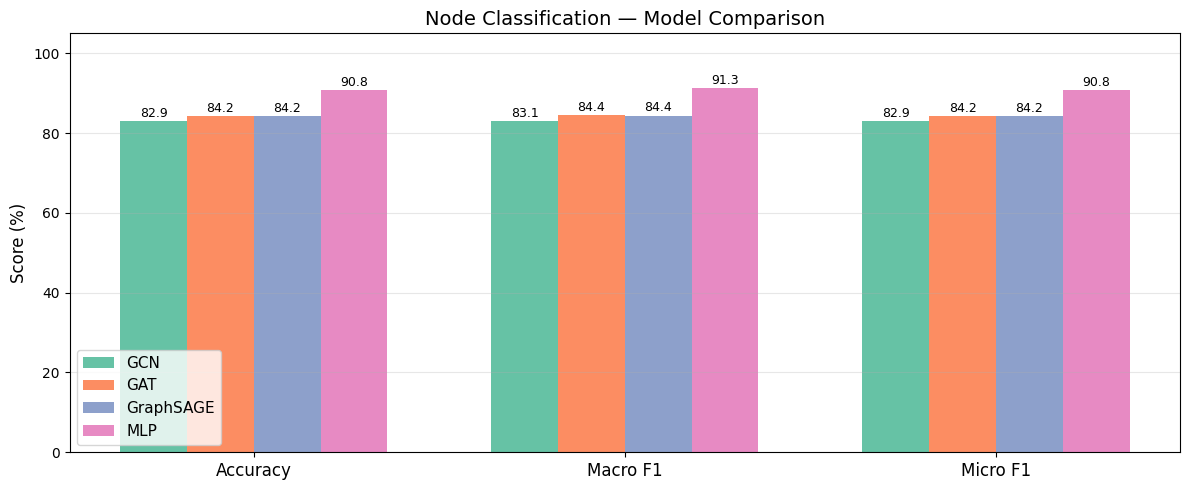

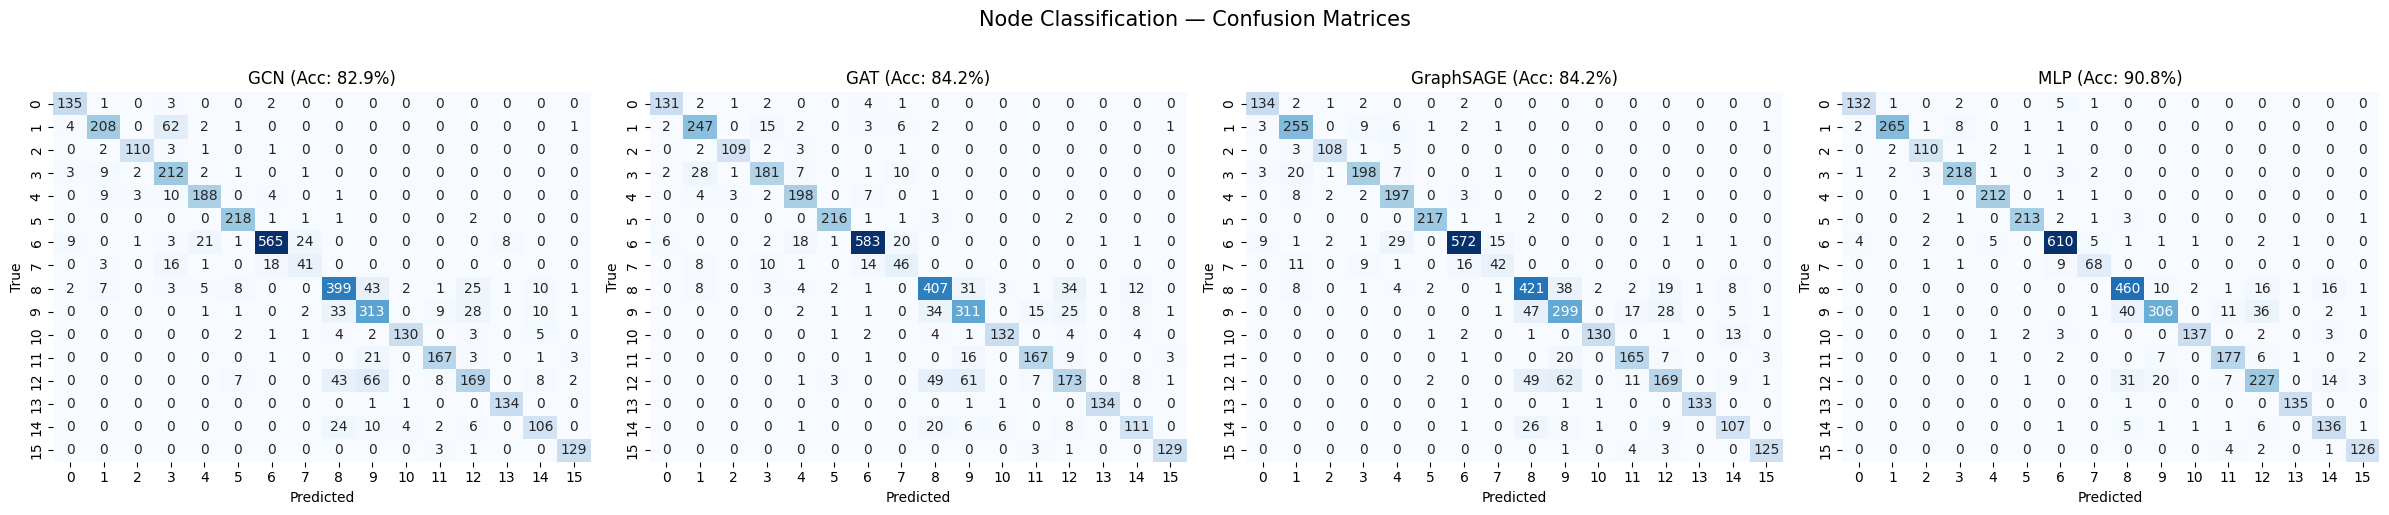

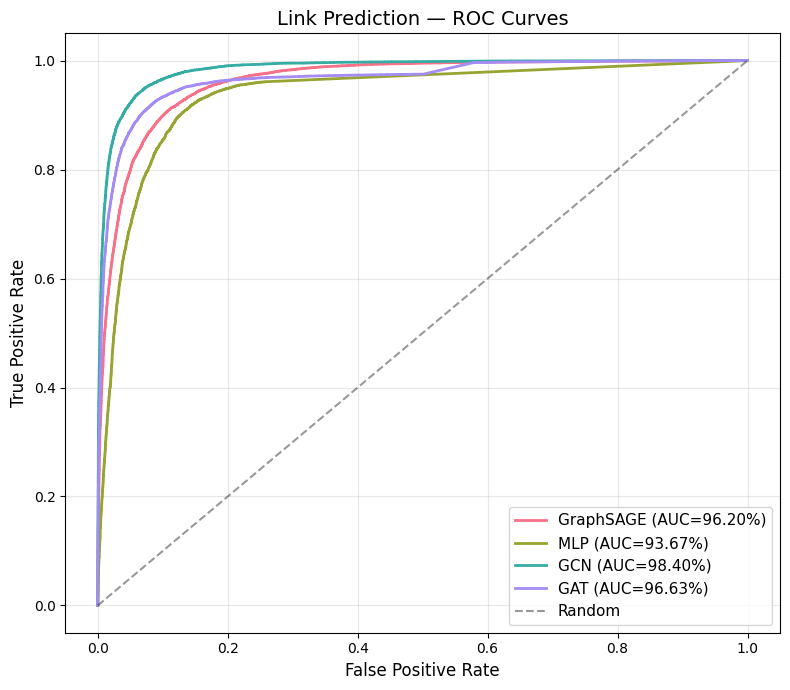


=== LINK PREDICTION COMPARISON ===


,Model,AUC,Accuracy,F1
0,GraphSAGE,96.199418,89.724156,90.045452
1,MLP,93.667585,88.677494,89.034255
2,GCN,98.396278,93.820572,93.858728
3,GAT,96.633146,91.758185,91.852909


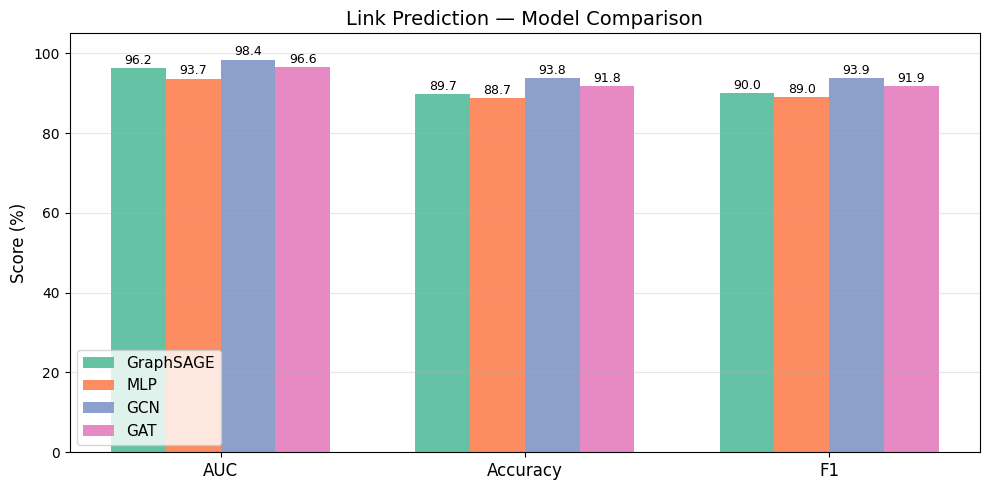

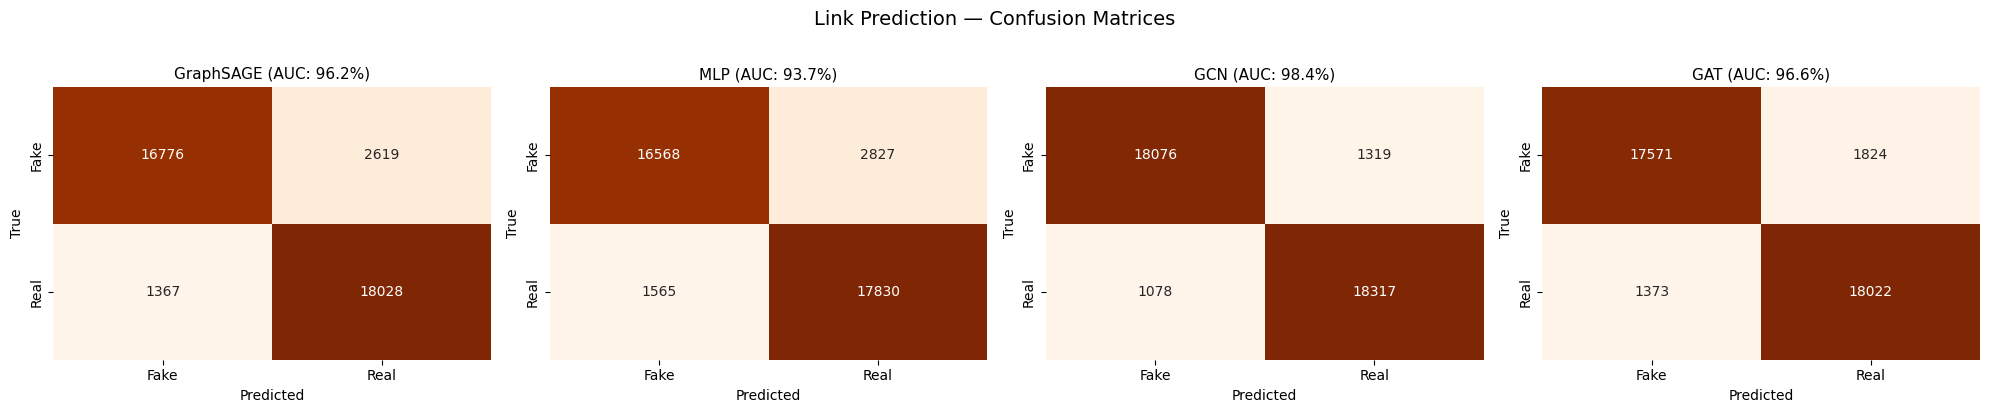

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score, f1_score

# ============================================================
# 1. NODE CLASSIFICATION — Comparative Bar Chart
# ============================================================
from sklearn import metrics as skmetrics

# Collect predictions for all node classification models
nc_models = {}

# GCN
y_pred_gcn_nc = np.argmax(best_model.predict(X_input, batch_size=len(X_input)), axis=1)
nc_models['GCN'] = y_pred_gcn_nc[test_mask]

# GAT
y_pred_gat_nc = best_gat_model.predict(X_full, batch_size=X_full.shape[0]).argmax(axis=1)
nc_models['GAT'] = y_pred_gat_nc[test_mask]

# GraphSAGE
y_pred_sage_nc = best_sage_model.predict(X_full, batch_size=X_full.shape[0]).argmax(axis=1)
nc_models['GraphSAGE'] = y_pred_sage_nc[test_mask]

# MLP
y_pred_mlp_nc = best_mlp_model.predict(X_test_mlp).argmax(axis=1)
nc_models['MLP'] = y_pred_mlp_nc

y_true_nc = y_input[test_mask]

# Build metrics table
nc_rows = []
for name, preds in nc_models.items():
    nc_rows.append({
        'Model': name,
        'Accuracy': skmetrics.accuracy_score(y_true_nc, preds) * 100,
        'Macro F1': skmetrics.f1_score(y_true_nc, preds, average='macro') * 100,
        'Micro F1': skmetrics.f1_score(y_true_nc, preds, average='micro') * 100,
        'Macro Precision': skmetrics.precision_score(y_true_nc, preds, average='macro') * 100,
        'Macro Recall': skmetrics.recall_score(y_true_nc, preds, average='macro') * 100,
    })
nc_df = pd.DataFrame(nc_rows)
print("=== NODE CLASSIFICATION COMPARISON ===")
display(nc_df)

# Bar chart
fig, ax = plt.subplots(figsize=(12, 5))
metrics_to_plot = ['Accuracy', 'Macro F1', 'Micro F1']
x = np.arange(len(metrics_to_plot))
width = 0.18
colors = sns.color_palette("Set2", len(nc_models))

for i, (name, _) in enumerate(nc_models.items()):
    vals = [nc_df[nc_df['Model'] == name][m].values[0] for m in metrics_to_plot]
    bars = ax.bar(x + i * width, vals, width, label=name, color=colors[i])
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{v:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics_to_plot, fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Node Classification — Model Comparison', fontsize=14)
ax.legend(fontsize=11)
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('nc_comparison_bar.png', dpi=300)
plt.show()

# ============================================================
# 2. NODE CLASSIFICATION — Confusion Matrices (2x2 grid)
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, (name, preds) in zip(axes, nc_models.items()):
    cm = confusion_matrix(y_true_nc, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=range(16), yticklabels=range(16), cbar=False)
    acc = skmetrics.accuracy_score(y_true_nc, preds) * 100
    ax.set_title(f'{name} (Acc: {acc:.1f}%)', fontsize=12)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.suptitle('Node Classification — Confusion Matrices', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('nc_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# 3. LINK PREDICTION — ROC Curves Overlay
# ============================================================
y_true_lp = y_test_link.numpy()

lp_scores = {
    'GraphSAGE': link_model.predict(x_test_edges, verbose=0).flatten(),
    'MLP':       mlp_link_model.predict(x_test_edges, verbose=0).flatten(),
    'GCN':       gcn_link_model.predict(x_test_edges, verbose=0).flatten(),
    'GAT':       gat_link_model.predict(x_test_edges, verbose=0).flatten(),
}

fig, ax = plt.subplots(figsize=(8, 7))
colors_lp = sns.color_palette("husl", len(lp_scores))

for (name, scores), color in zip(lp_scores.items(), colors_lp):
    fpr, tpr, _ = roc_curve(y_true_lp, scores)
    auc = roc_auc_score(y_true_lp, scores)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc*100:.2f}%)', color=color, linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('Link Prediction — ROC Curves', fontsize=14)
ax.legend(fontsize=11, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lp_roc_overlay.png', dpi=300)
plt.show()

# ============================================================
# 4. LINK PREDICTION — Comparative Bar Chart
# ============================================================
lp_thresholds = {
    'GraphSAGE': best_threshold,
    'MLP':       best_thr_mlp,
    'GCN':       best_thr_gcn,
    'GAT':       best_thr_gat,
}

lp_rows = []
for name, scores in lp_scores.items():
    thr = lp_thresholds[name]
    preds_bin = (scores >= thr).astype(int)
    lp_rows.append({
        'Model': name,
        'AUC': roc_auc_score(y_true_lp, scores) * 100,
        'Accuracy': accuracy_score(y_true_lp, preds_bin) * 100,
        'F1': f1_score(y_true_lp, preds_bin) * 100,
    })
lp_df = pd.DataFrame(lp_rows)
print("\n=== LINK PREDICTION COMPARISON ===")
display(lp_df)

fig, ax = plt.subplots(figsize=(10, 5))
lp_metrics = ['AUC', 'Accuracy', 'F1']
x = np.arange(len(lp_metrics))
width = 0.18

for i, name in enumerate(lp_scores.keys()):
    vals = [lp_df[lp_df['Model'] == name][m].values[0] for m in lp_metrics]
    bars = ax.bar(x + i * width, vals, width, label=name, color=colors[i])
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{v:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(lp_metrics, fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Link Prediction — Model Comparison', fontsize=14)
ax.legend(fontsize=11)
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('lp_comparison_bar.png', dpi=300)
plt.show()

# ============================================================
# 5. LINK PREDICTION — Confusion Matrices
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, scores) in zip(axes, lp_scores.items()):
    thr = lp_thresholds[name]
    preds_bin = (scores >= thr).astype(int)
    cm = confusion_matrix(y_true_lp, preds_bin)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax,
                xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"], cbar=False)
    auc_val = roc_auc_score(y_true_lp, scores) * 100
    ax.set_title(f'{name} (AUC: {auc_val:.1f}%)', fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.suptitle('Link Prediction — Confusion Matrices', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('lp_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

In [60]:
import os, pickle, json
import numpy as np

os.makedirs("saved_models", exist_ok=True)

# ── WEIGHTS (în loc de .keras — evităm get_config()) ─────────────────────────
best_model.save_weights("saved_models/gcn_nc_weights.weights.h5")
best_gat_model.save_weights("saved_models/gat_nc_weights.weights.h5")
best_sage_model.save_weights("saved_models/sage_nc_weights.weights.h5")
best_mlp_model.save_weights("saved_models/mlp_nc_weights.weights.h5")

gcn_link_model.save_weights("saved_models/gcn_lp_weights.weights.h5")
gat_link_model.save_weights("saved_models/gat_lp_weights.weights.h5")
link_model.save_weights("saved_models/sage_lp_weights.weights.h5")
mlp_link_model.save_weights("saved_models/mlp_lp_weights.weights.h5")

# ── SBERT ENCODER CONFIG ──────────────────────────────────────────────────────
with open("saved_models/encoder_config.pkl", "wb") as f:
    pickle.dump({"type": "sbert", "model_name": "all-mpnet-base-v2"}, f)

# ── GRAPH DATA ────────────────────────────────────────────────────────────────
np.savez(
    "saved_models/graph_data.npz",
    X_full      = X_full,
    y_full      = y_full,
    edge_index  = data.edge_index.numpy(),
    train_mask  = data.train_mask.numpy(),
    val_mask    = data.val_mask.numpy(),
    test_mask   = data.test_mask.numpy(),
    node_names  = np.array(final_asins),
    class_names = np.array(TARGET_CLASSES),
)

# ── ASIN → INDEX ──────────────────────────────────────────────────────────────
with open("saved_models/asin_to_idx.pkl", "wb") as f:
    pickle.dump({asin: int(idx) for idx, asin in enumerate(final_asins)}, f)

# ── CONFIG (HP + thresholds) — necesar pentru reconstrucția modelelor ─────────
lp_config = {
    "thresholds": {
        "GraphSAGE": float(best_threshold),
        "MLP":       float(best_thr_mlp),
        "GCN":       float(best_thr_gcn),
        "GAT":       float(best_thr_gat),
    },
    "num_features": int(X_full.shape[1]),
    "num_classes":  16,
    "num_nodes":    int(X_full.shape[0]),
    "target_classes": TARGET_CLASSES,
    # Hyperparametri pentru reconstrucția modelelor
    "hp": {
        "gcn_nc": {
            "out_feat": int(best_hp.get("out_feat")),
            "dropout":  float(best_hp.get("dropout")),
        },
        "gat_nc": {
            "num_heads": int(best_hps_gat.get("num_heads")),
            "out_feat":  int(best_hps_gat.get("out_feat")),
            "dropout":   float(best_hps_gat.get("dropout")),
        },
        "sage_nc": {
            "out_feat":   int(best_hps_sage.get("out_feat")),
            "dropout":    float(best_hps_sage.get("dropout")),
            "normalize":  bool(best_hps_sage.get("normalize")),
        },
        "mlp_nc": {
            "units_1":   int(best_hps_mlp.get("units_1")),
            "dropout_1": float(best_hps_mlp.get("dropout_1")),
            "units_2":   int(best_hps_mlp.get("units_2")),
            "dropout_2": float(best_hps_mlp.get("dropout_2")),
        },
        "sage_lp": {
            "out_feat": int(best_hps_link.get("out_feat")),
            "dropout":  float(best_hps_link.get("dropout")),
        },
        "mlp_lp": {
            "hidden_dim": int(best_hps_mlp_link.get("hidden_dim")),
            "dropout":    float(best_hps_mlp_link.get("dropout")),
        },
        "gcn_lp": {
            "out_feat": int(best_hps_gcn_link.get("out_feat")),
            "dropout":  float(best_hps_gcn_link.get("dropout")),
        },
        "gat_lp": {
            "num_heads": int(best_hps_gat_link.get("num_heads")),
            "out_feat":  int(best_hps_gat_link.get("out_feat")),
            "dropout":   float(best_hps_gat_link.get("dropout")),
        },
    }
}

with open("saved_models/lp_config.json", "w") as f:
    json.dump(lp_config, f, indent=2)

print("✅ Salvat:", os.listdir("saved_models"))

✅ Salvat: ['asin_to_idx.pkl', 'encoder_config.pkl', 'gat_lp_weights.weights.h5', 'gat_nc_weights.weights.h5', 'gcn_lp_weights.weights.h5', 'gcn_nc_weights.weights.h5', 'graph_data.npz', 'lp_config.json', 'mlp_lp_weights.weights.h5', 'mlp_nc_weights.weights.h5', 'sage_lp_weights.weights.h5', 'sage_nc_weights.weights.h5', 'tfidf_vectorizer.pkl']
